# Stochastic gene expression quantifies mRNA heterogeneity in cancer cell populations with extrachromosomal DNA

In [1]:
import logging
import argparse
import numpy as np
import h5py
import os
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from matplotlib.offsetbox import AnchoredText
import pyreadr
import warnings
warnings.filterwarnings('ignore')

## Generation of simulated mRNA distributions from ecDNA distributions

We have generated the ecDNA distribution Summary_3_20.txt using the code from [Lange et al., 2022](https://www.nature.com/articles/s41588-022-01177-x#code-availability) using selection coefficient, $s=3$, and initial no. of ecDNA copies, $n=20$.

### 1. From simulated ecDNA distribution

A single stochastic gene expression simulation can be performed by running the command below. However, we recommend using a cluster to perform parallel runs. An example script (script.sh) is provided in the simulated_ecdna_data directory 

In [ ]:
run './simulated_ecdna_data/exps.py' --gene_dist_file ./simulated_ecdna_data/Summary_3_20.txt --ka 0.1 --kd 0.1 --jp 1000.0 --kp 1.0 --output_file ./simulated_ecdna_data/mrna_3_20_01_01_1000_1.txt

We can now use the simulated mRNA distributions in simulated_ecdna_data/mrna_dists to produce the plots in Figures 1 and 2. First we compute and plot histograms of the simulated ecDNA and mRNA data

Text(0, 0.5, 'cell count')

<Figure size 640x480 with 0 Axes>

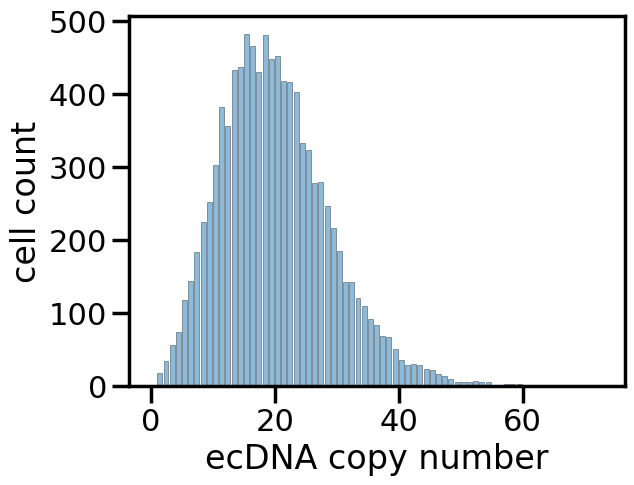

In [3]:
# load txt file containing ecDNA counts
ecdna_counts = np.loadtxt('./simulated_ecdna_data/Summary_3_20.txt')
# only consider data upto first 100 runs
ecdna_counts_flat = ecdna_counts[:100].flatten()
# only take cells with a nonzero count of ecDNA
ecdna_counts_nonzero = ecdna_counts_flat[ecdna_counts_flat!=0].astype('int')
# compute histogram
bin_size_ecdna = 1 # resolution of measurement
ecdna_hist, bin_edges = np.histogram(ecdna_counts_nonzero,
                                     bins=np.arange(0,
                                                    ecdna_counts_nonzero.max()+bin_size_ecdna+1,
                                                    bin_size_ecdna))

sns.set_context('poster', font_scale=1.0)
plt.figure()
plt.figure()
plt.bar(bin_edges[:-1], ecdna_hist, align='edge',
           fill=True, ec='k', lw=0.5, alpha=0.5, label='ecDNA')
plt.xlabel('ecDNA copy number')
plt.ylabel('cell count')

Text(0.5, 0, 'mRNA copy number')

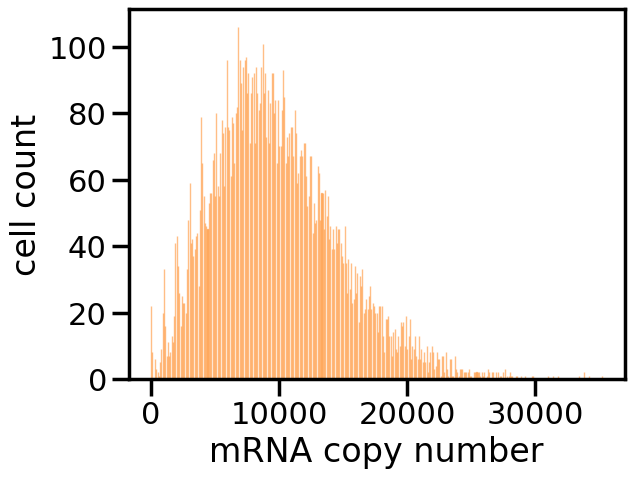

In [4]:
# load txt file containing mRNA counts
mrna_counts = np.loadtxt('./simulated_ecdna_data/mrna_dists/mrna_3_20_01_01_1000_1.txt').astype('int')
avg = 1000 # mrna production rate
mrna_pmfs = []
bin_size_mrna = 100
# compute histogram
mrna_counts_hist, bin_edges_counts = np.histogram(mrna_counts,
                                         bins=np.arange(0,
                                                        mrna_counts.max()+bin_size_mrna+1,
                                                        bin_size_mrna))

plt.figure()
plt.bar(bin_edges_counts[:-1], mrna_counts_hist, align='edge',
               fill=True, ec='tab:orange', lw=1.0, fc='tab:orange', alpha=0.5, label='mRNA: $k_a=0.1, k_d=0.1$')
plt.ylabel('cell count')
plt.xlabel('mRNA copy number')

Text(0, 0.5, 'mRNA copy number')

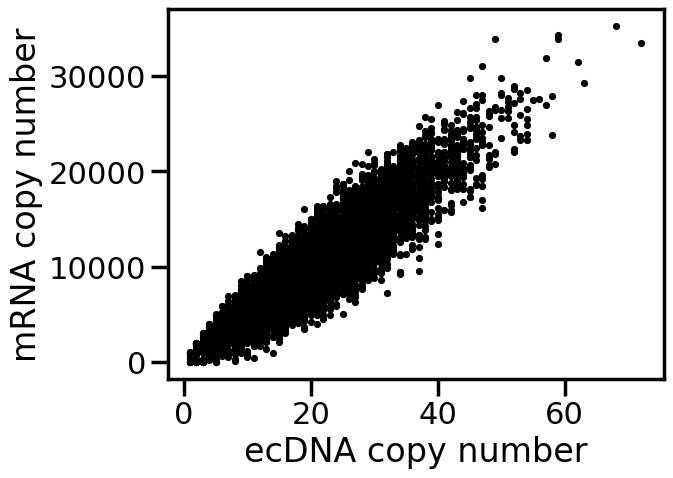

In [5]:
# plot the joint distribution
plt.figure()
plt.scatter(ecdna_counts_nonzero, mrna_counts, s=10, fc='k')
plt.xlabel('ecDNA copy number')
plt.ylabel('mRNA copy number')

Next, we define a function to produce the plots in Figure 2 and show an example plot for $r_a, r_d = 1$

In [6]:
def plot_ecdna_mrna_joint_dist(ecdna_file, mrna_file, bin_size_ecdna=1, bin_size_mrna=100, cbar=False, scatter=True):
    # read and process ecdna counts
    ecdna_counts = np.loadtxt(ecdna_file).astype('int')
    ecdna_counts_flat = ecdna_counts[:100].flatten()
    ecdna_counts_nonzero = ecdna_counts_flat[ecdna_counts_flat!=0]
    # read mrna counts
    mrna_counts = np.loadtxt(mrna_file).astype('int')

    # repeat ecdna counts for multiple realisations
    if len(mrna_counts.shape)>1 and mrna_counts.shape[1]>1:
        ecdna_counts_nonzero = np.repeat(ecdna_counts_nonzero, mrna_counts.shape[1])
        mrna_counts = mrna_counts.flatten()

    # compute stdevs and correlation
    R = np.corrcoef(ecdna_counts_nonzero, mrna_counts)
    stdev_ecdna = np.std(ecdna_counts_nonzero)
    stdev_mrna = np.std(mrna_counts)

    # linear regression 
    lin_reg = np.polyfit(ecdna_counts_nonzero, mrna_counts, 1)

    # generate bins for histograms
    ecdna_bins = np.arange(0, ecdna_counts_nonzero.max()+bin_size_ecdna+1, bin_size_ecdna)
    mrna_bins = np.arange(0, (ecdna_counts_nonzero.max()*1000)+bin_size_mrna+1, bin_size_mrna)

    # generate plot
    sns.set_context('poster', font_scale=0.8)
    g = sns.JointGrid(marginal_ticks=True)
    g.ax_joint.set_xlabel('ecDNA copy number')
    g.ax_joint.set_ylabel('mRNA copy number')
    if cbar: g.fig.add_axes((1.0,0.05,0.05,0.9))
    if not scatter: sns.histplot(x=ecdna_counts_nonzero, y=mrna_counts, ax=g.ax_joint, stat='count', 
                 bins=[ecdna_bins, mrna_bins], cmap='rocket_r', alpha=1.0, thresh=None,
                 cbar=cbar, cbar_ax=g.fig.axes[-1])
    sns.lineplot(x=ecdna_counts_nonzero, y=ecdna_counts_nonzero*1000, ax=g.ax_joint, linestyle='-.', color='k')#,
    sns.lineplot(x=ecdna_counts_nonzero, y=ecdna_counts_nonzero*lin_reg[0]+lin_reg[1], ax=g.ax_joint, 
                 linestyle='--', color='r')
    if scatter: sns.scatterplot(x=ecdna_counts_nonzero, y=mrna_counts, ax=g.ax_joint, marker=".",
                    alpha=0.4, color="k")
    ax_marg_ecdna = g.ax_marg_x
    ax_marg_mrna = ax_marg_ecdna.twiny().twinx()
    sns.histplot(x=ecdna_counts_nonzero, ax=ax_marg_ecdna, bins=ecdna_bins, stat='count', color='tab:blue', 
                 fill=True, edgecolor=None, alpha=0.2)
    sns.histplot(x=mrna_counts, ax=ax_marg_mrna, bins=mrna_bins, stat='count', color='tab:orange', 
                 fill=True, edgecolor=None, alpha=1.0)
    g.ax_marg_y.set_visible(False)
    plt.show()
    
    return R, lin_reg

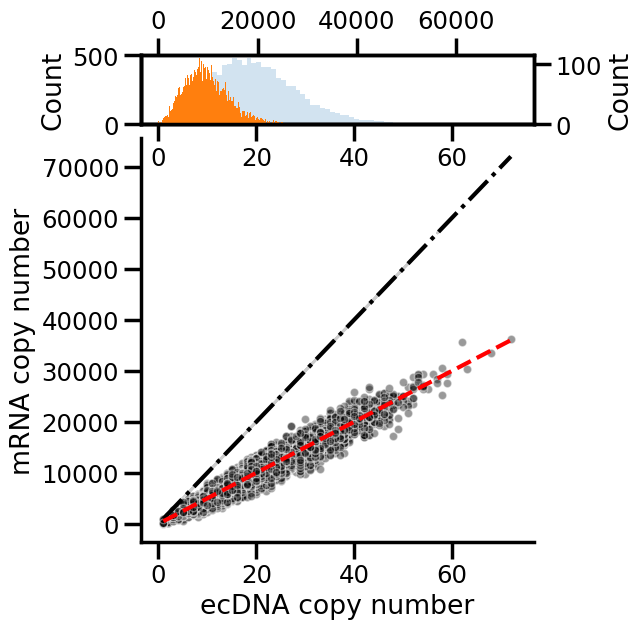

(array([[1.        , 0.96012189],
        [0.96012189, 1.        ]]),
 array([499.83088533,  -1.04739231]))

In [11]:
plot_ecdna_mrna_joint_dist('./simulated_ecdna_data/Summary_3_20.txt', 
                           './simulated_ecdna_data/mrna_dists/mrna_3_20_1_1_1000_1.txt')

### 2. From experimentally measured ecDNA distributions in Stoeber et al

Next, we use the ecDNA measurements in the data in Stoeber et al to simulate mRNA distributions for different values of $r_a, r_d$.

In [16]:
# load data into pandas dataframe
r_obj2 = pyreadr.read_r("./experimental_ecdna_mrna_data/Stoeber_et_al_data/2024_02_06_ampl_reconst_data.rds")
exp_df = pd.DataFrame.from_dict(r_obj2[None])#.data)
exp_df.replace('IMR5/75', 'IMR575', inplace=True)
exp_df.replace('MYCN gene', 'MYCNgene', inplace=True)
exp_df

,expr,cn,hgnc,gene,amplicon,cell_line
rownames,,,,,,
plate89_G5.p9,1258.53,154.0,MYT1L,ENSG00000186487.13,MYCN,TR14
plate89_D3.p9,1108.58,109.0,MYT1L,ENSG00000186487.13,MYCN,TR14
plate89_B10.p8,577.89,188.0,MYT1L,ENSG00000186487.13,MYCN,TR14
plate89_D6.p9,1580.14,151.0,MYT1L,ENSG00000186487.13,MYCN,TR14
plate89_H5.p8,635.65,31.0,MYT1L,ENSG00000186487.13,MYCN,TR14
...,...,...,...,...,...,...
p1011_A9.p109,17.00,17.0,GKN2,ENSG00000183607.5,HSR,IMR575
p1011_F7.p109,10.00,10.0,GKN2,ENSG00000183607.5,HSR,IMR575
p1011_D9.p109,16.00,16.0,GKN2,ENSG00000183607.5,HSR,IMR575


In [ ]:
# Note out of 47 total (cell line, amplicon, gene) combinations only 26 are unique - see same_gene_distribs.txt
# in Stoeber_et_al_data/unique for details. Each line of genes represents a unique ecDNA distribution (e.g. in the cell line CHP212, in the MYCN amplicon, 
# DDX1, GREB1, LPIN1, MYCN, TRIB2 all have the same underlying ecDNA distribution 

# generate directories for mRNA distributions
grouped = exp_df.groupby(['cell_line', 'amplicon', 'hgnc'], observed=True)

for name, group in grouped:
    cl, a, g = name
    exp_data_dir = './experimental_ecdna_mrna_data/Stoeber_et_al_data/unique/'
    gene_dist_files = []
    for i in os.listdir(exp_data_dir):
        if os.path.isfile(os.path.join(exp_data_dir,i)) and 'ecdna_' in i:
            gene_dist_files.append(i)
gene_dist_files = np.sort(gene_dist_files)
mrna_dist_dirs = []
for g in gene_dist_files:
    mrna_dir_name = g.replace('ecdna', 'gene_exp_sims').split('.')[0]
    mrna_dist_dirs.append('./experimental_ecdna_mrna_data/Stoeber_et_al_sims/'+mrna_dir_name+'/')

from pathlib import Path
for dir in mrna_dist_dirs:
    Path(dir).mkdir(parents=True, exist_ok=True)

In [ ]:
# Simulations for a single ecDNA distribution can be run using the following command
run './experimental_ecdna_mrna_data/exps_Stoeber_data.py' --gene_dist_file ./experimental_ecdna_mrna_data/Stoeber_et_al_data/unique/ecdna_CHP212_MYCN_MYCN.txt --ka 0.01 --kd 0.01 --jp 1000.0 --kp 1.0 --output_file ./experimental_ecdna_mrna_data/Stoeber_et_al_sims/mrna_0_0.txt --no_traj 10

We simulated mRNA distributions for all unique ecDNA distributions and used these to perform parameter estimation

## Parameter estimation by comparing to experimental mRNA distributions in Stoeber et al data

In [41]:
# loading all data into dataframe
ka_num = 15
kd_num = 15
all_sim_dir = './experimental_ecdna_mrna_data/Stoeber_et_al_sims/'
sim_data = []
for sim_dir in os.listdir(all_sim_dir):
    cell_line, amplicon, hgnc = sim_dir.split('_')[3:]
    exp = exp_df[(exp_df['cell_line']==cell_line) & (exp_df['amplicon']==amplicon) & (exp_df['hgnc']==hgnc)]['expr'].values
    cn = exp_df[(exp_df['cell_line']==cell_line) & (exp_df['amplicon']==amplicon) & (exp_df['hgnc']==hgnc)]['cn'].values
    dir = all_sim_dir+sim_dir
    params = np.loadtxt(dir+'/ka_kd.txt')[:int(ka_num*kd_num)].reshape([ka_num,kd_num,2])
    for i in range(0,len(params)):
        for j in range(0,len(params)):
            ka, kd = params[i,j]
            mrna_count = np.loadtxt(dir+'/mrna_{}_{}.txt'.format(str(i),str(j)))
            for traj_no, traj in enumerate(mrna_count.T):
                sim_data.append((cell_line, amplicon, hgnc, ka, kd, traj_no, traj, exp, cn))

sim_df = pd.DataFrame(sim_data, columns=['cell_line', 'amplicon', 'hgnc', '$k_a$', '$k_d$', 'trajectory', 'expr', 'expr_true', 'cn'])
sim_df

,cell_line,amplicon,hgnc,$k_a$,$k_d$,trajectory,expr,expr_true,cn
0,TR14,MDM2,YEATS4,0.01,0.01,0,"[21976.0, 17376.0, 44781.0, 73522.0, 14771.0, ...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
1,TR14,MDM2,YEATS4,0.01,0.01,1,"[23089.0, 11117.0, 40540.0, 73256.0, 10375.0, ...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
2,TR14,MDM2,YEATS4,0.01,0.01,2,"[25681.0, 12939.0, 36992.0, 75352.0, 8997.0, 3...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
3,TR14,MDM2,YEATS4,0.01,0.01,3,"[23210.0, 15423.0, 48460.0, 73824.0, 9916.0, 4...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
4,TR14,MDM2,YEATS4,0.01,0.01,4,"[23892.0, 9913.0, 41008.0, 64540.0, 12903.0, 4...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
...,...,...,...,...,...,...,...,...,...
105745,TR14,MDM2,LYZ,10.00,10.00,5,"[27294.0, 16663.0, 55224.0, 81919.0, 13608.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
105746,TR14,MDM2,LYZ,10.00,10.00,6,"[27218.0, 15784.0, 54666.0, 86991.0, 12640.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
105747,TR14,MDM2,LYZ,10.00,10.00,7,"[29636.0, 17821.0, 56634.0, 83408.0, 14519.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."
105748,TR14,MDM2,LYZ,10.00,10.00,8,"[28168.0, 18137.0, 57715.0, 83543.0, 13244.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ..."


In [42]:
# compute Wasserstein distance between experimentally measured mRNA copy numbers and simulated mRNA copy numbers and add to dataframe
for index, data in sim_df.iterrows():
    sim_df.loc[index, 'Wasserstein distance'] = scipy.stats.wasserstein_distance(data['expr_true'], data['expr'])
sim_df

,cell_line,amplicon,hgnc,$k_a$,$k_d$,trajectory,expr,expr_true,cn,Wasserstein distance
0,TR14,MDM2,YEATS4,0.01,0.01,0,"[21976.0, 17376.0, 44781.0, 73522.0, 14771.0, ...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",25754.577581
1,TR14,MDM2,YEATS4,0.01,0.01,1,"[23089.0, 11117.0, 40540.0, 73256.0, 10375.0, ...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",26096.125968
2,TR14,MDM2,YEATS4,0.01,0.01,2,"[25681.0, 12939.0, 36992.0, 75352.0, 8997.0, 3...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",26152.298011
3,TR14,MDM2,YEATS4,0.01,0.01,3,"[23210.0, 15423.0, 48460.0, 73824.0, 9916.0, 4...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",26162.744247
4,TR14,MDM2,YEATS4,0.01,0.01,4,"[23892.0, 9913.0, 41008.0, 64540.0, 12903.0, 4...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",26312.405538
...,...,...,...,...,...,...,...,...,...,...
105745,TR14,MDM2,LYZ,10.00,10.00,5,"[27294.0, 16663.0, 55224.0, 81919.0, 13608.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",35472.727796
105746,TR14,MDM2,LYZ,10.00,10.00,6,"[27218.0, 15784.0, 54666.0, 86991.0, 12640.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",35554.114892
105747,TR14,MDM2,LYZ,10.00,10.00,7,"[29636.0, 17821.0, 56634.0, 83408.0, 14519.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",35579.964355
105748,TR14,MDM2,LYZ,10.00,10.00,8,"[28168.0, 18137.0, 57715.0, 83543.0, 13244.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",35519.270806


In [43]:
# choose accepted simulations: only simulations for which the Wasserstein distance between simulated and experimental mRNA distributions are among
# the 1% smallest distances for a given cell line, amplicon and gene are accepted
divisor = 100 # 1/(fraction of accepted entries), 100 = 1% of entries accepted
for cell_line in sim_df['cell_line'].unique():
    for gene in sim_df['hgnc'].unique():
        n_smallest = sim_df[(sim_df['cell_line']==cell_line) & (sim_df['hgnc']==gene)].shape[0]//divisor # number of acceptances that 1% corresponds to for each gene in each cell line
        thresh = sim_df[(sim_df['cell_line']==cell_line) & (sim_df['hgnc']==gene)].nsmallest(n_smallest, 'Wasserstein distance', keep='all')['Wasserstein distance'].max() # corresponding Wasserstein dist threshold
        sim_df.loc[(sim_df['cell_line']==cell_line) & (sim_df['hgnc']==gene) & (sim_df['Wasserstein distance']<=thresh),['accept']] = 1
        sim_df.loc[(sim_df['cell_line']==cell_line) & (sim_df['hgnc']==gene) & (sim_df['Wasserstein distance']>thresh),['accept']] = 0
sim_df = sim_df.astype({"accept": int})
sim_df[sim_df["accept"]==1]

,cell_line,amplicon,hgnc,$k_a$,$k_d$,trajectory,expr,expr_true,cn,Wasserstein distance,accept
701,TR14,MDM2,YEATS4,0.07,1.39,1,"[1662.0, 1560.0, 4945.0, 10469.0, 1465.0, 4099...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",189.337258,1
702,TR14,MDM2,YEATS4,0.07,1.39,2,"[1626.0, 1117.0, 5653.0, 10784.0, 2898.0, 2468...","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",232.328441,1
704,TR14,MDM2,YEATS4,0.07,1.39,4,"[4001.0, 1320.0, 2251.0, 6234.0, 1824.0, 6697....","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",165.556935,1
705,TR14,MDM2,YEATS4,0.07,1.39,5,"[3153.0, 1893.0, 4267.0, 8658.0, 1380.0, 4625....","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",226.527043,1
706,TR14,MDM2,YEATS4,0.07,1.39,6,"[1820.0, 2816.0, 4279.0, 8631.0, 1105.0, 4615....","[4491.39, 2452.47, 8266.09, 6831.56, 1163.89, ...","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",227.345323,1
...,...,...,...,...,...,...,...,...,...,...,...
103648,TR14,MDM2,LYZ,0.01,10.00,8,"[0.0, 5.0, 72.0, 231.0, 2.0, 75.0, 35.0, 0.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",63.652957,1
103649,TR14,MDM2,LYZ,0.01,10.00,9,"[4.0, 11.0, 157.0, 350.0, 154.0, 64.0, 0.0, 4....","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",51.141129,1
103791,TR14,MDM2,LYZ,0.02,10.00,1,"[67.0, 81.0, 34.0, 49.0, 288.0, 301.0, 149.0, ...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",131.491237,1
103795,TR14,MDM2,LYZ,0.02,10.00,5,"[82.0, 43.0, 372.0, 172.0, 11.0, 182.0, 312.0,...","[2.16, 3.64, 0.73, 1.97, 3.45, 0.0, 4.27, 103....","[56.0, 35.0, 111.0, 170.0, 27.0, 101.0, 40.0, ...",129.399839,1


Now we generate the best fit and posterior distribution plots in Figure 3 and 4

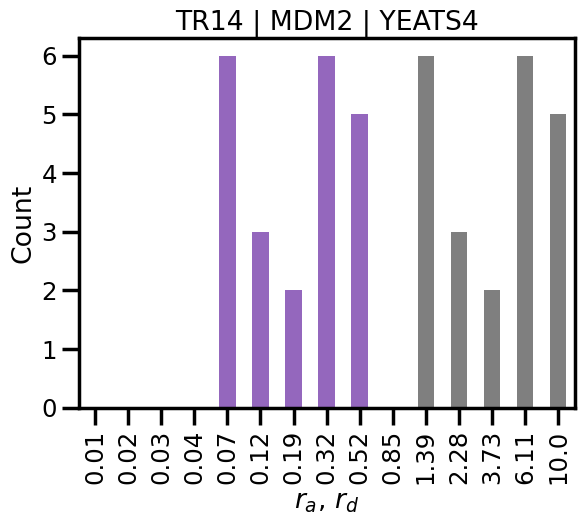

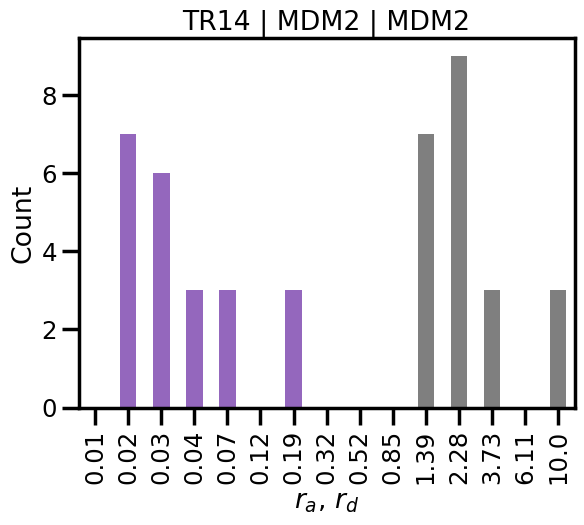

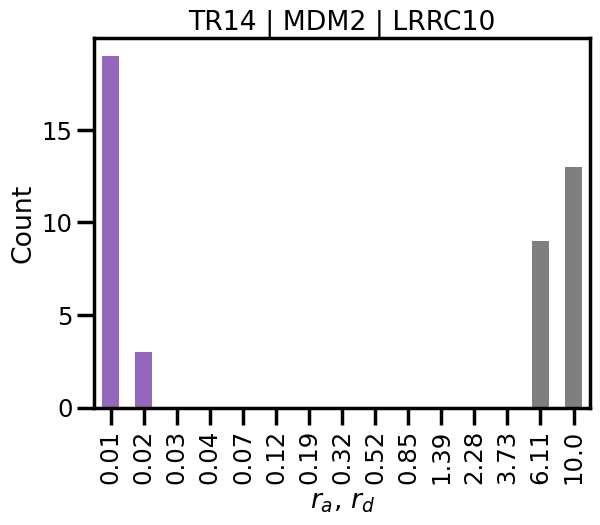

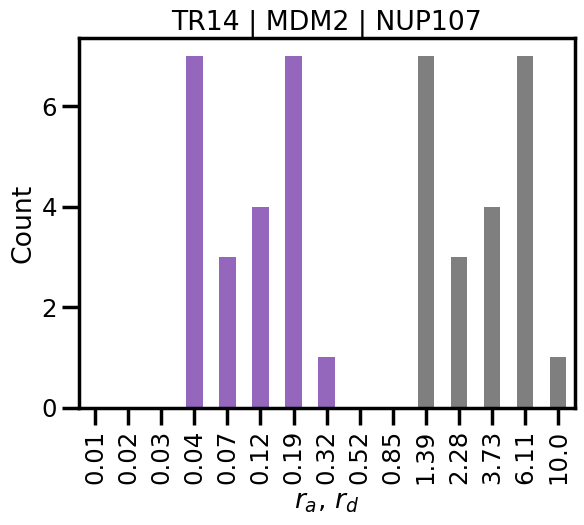

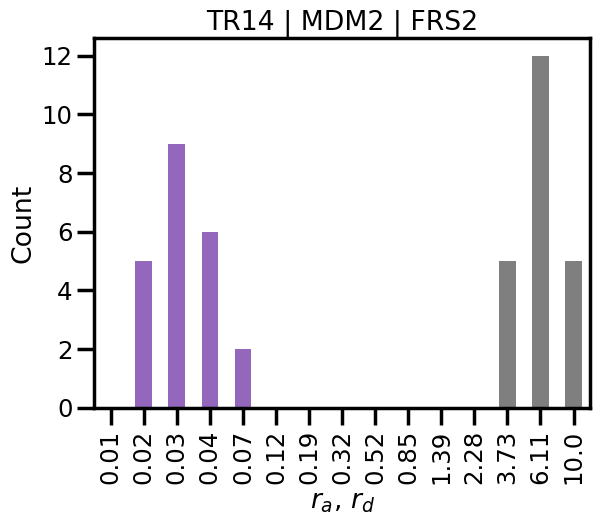

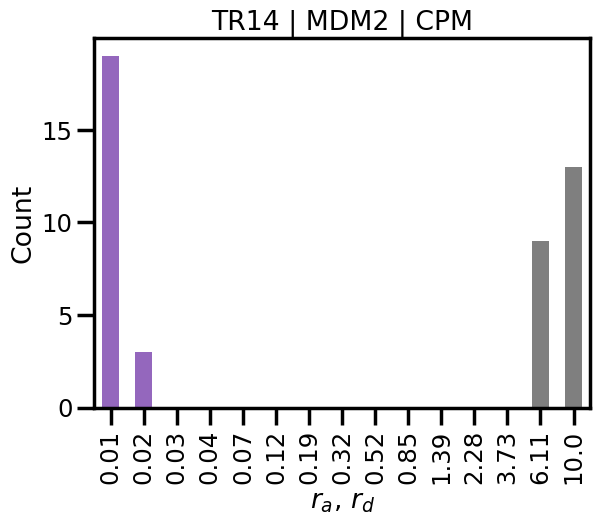

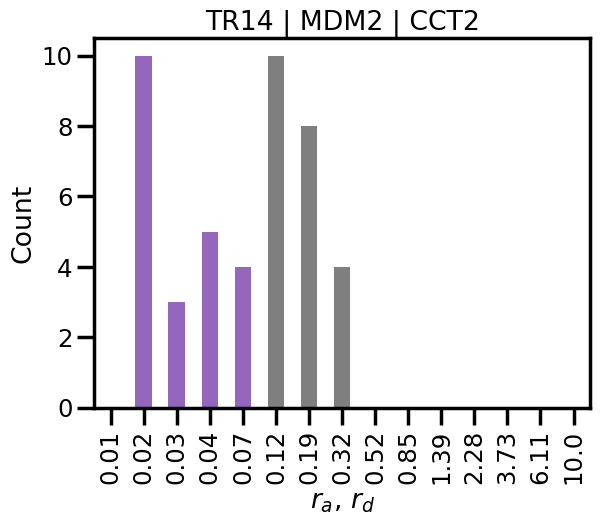

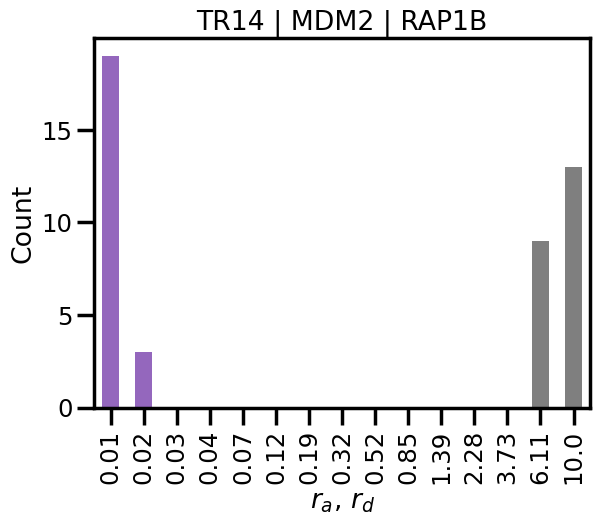

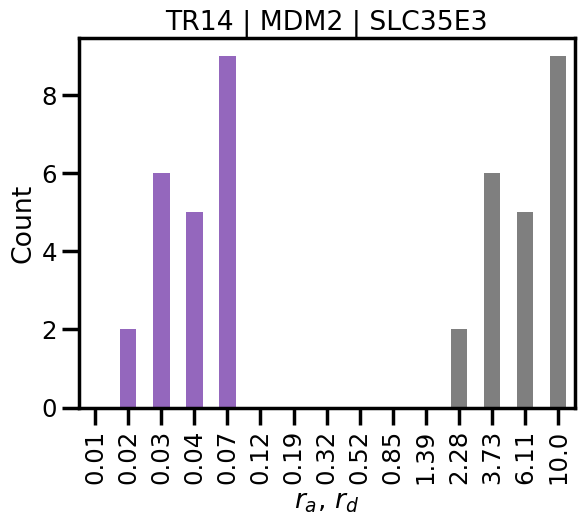

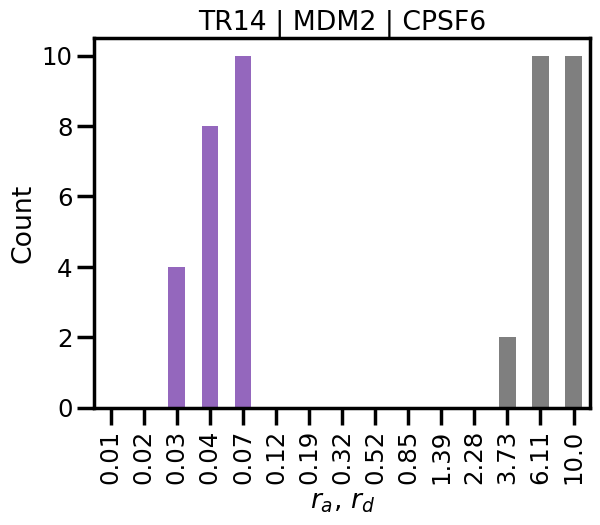

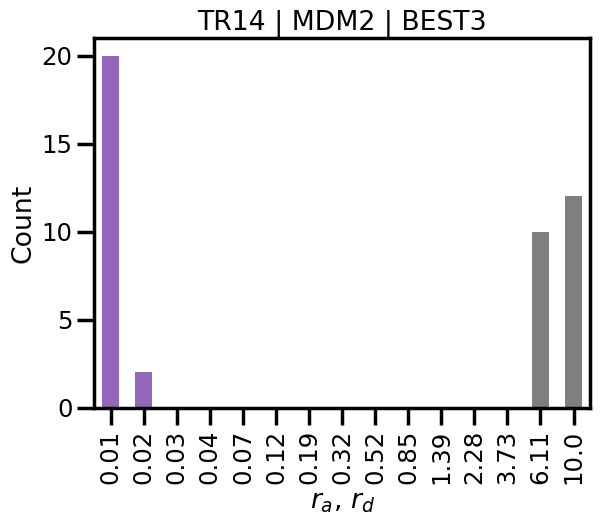

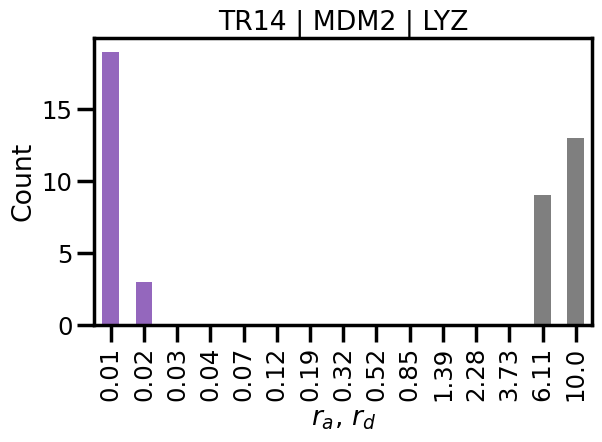

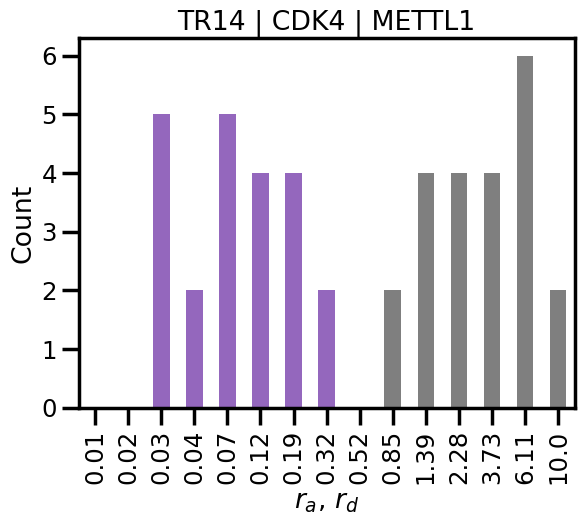

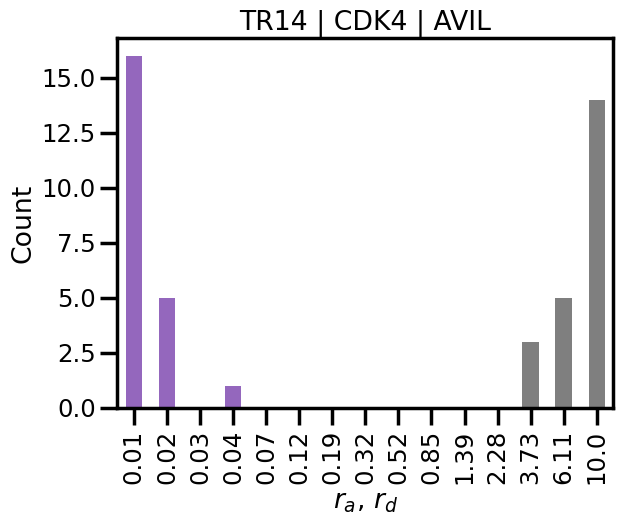

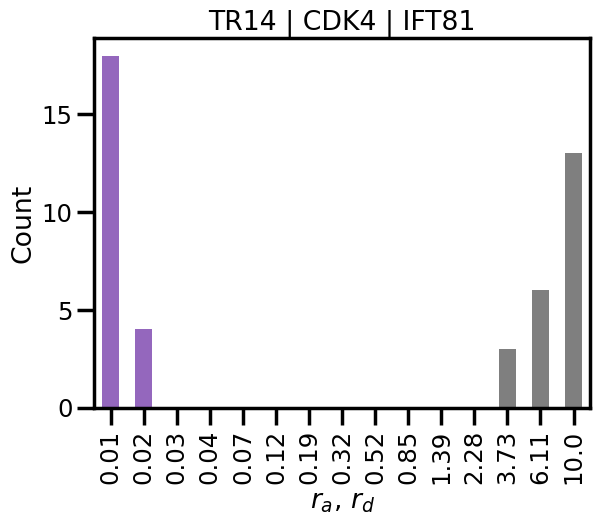

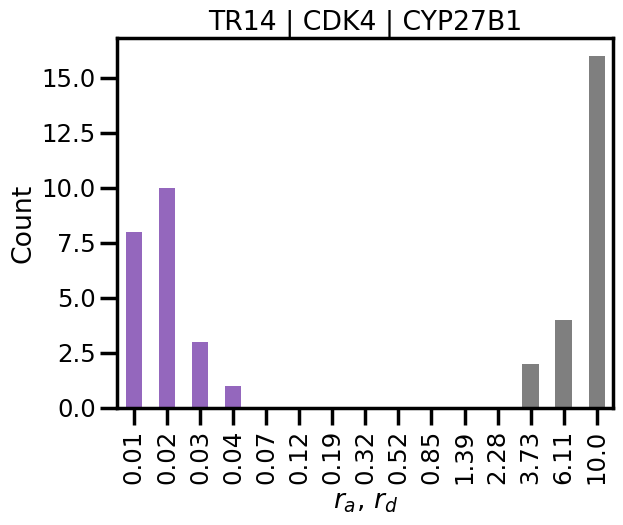

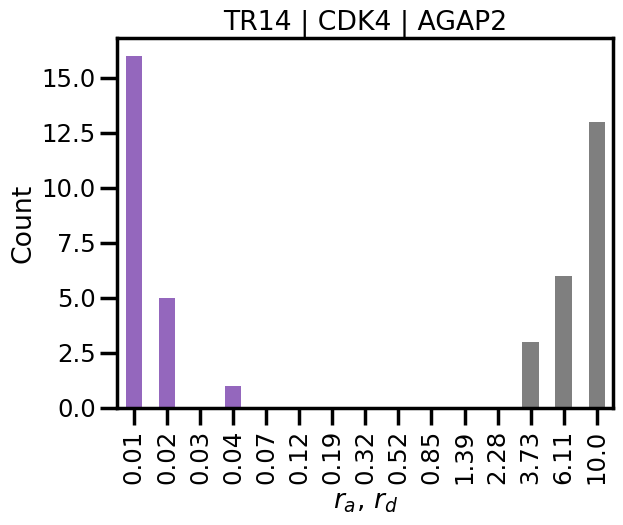

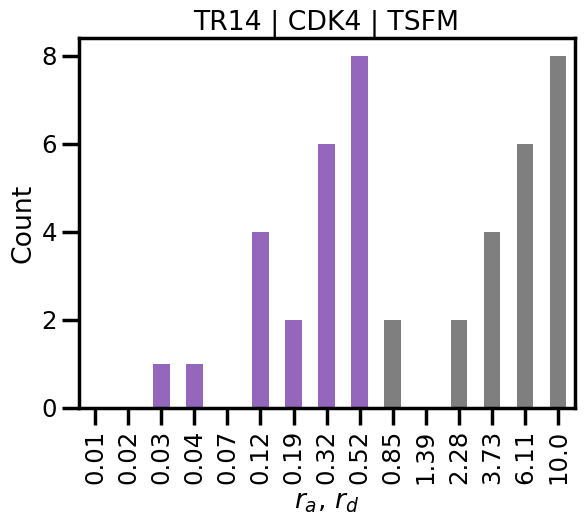

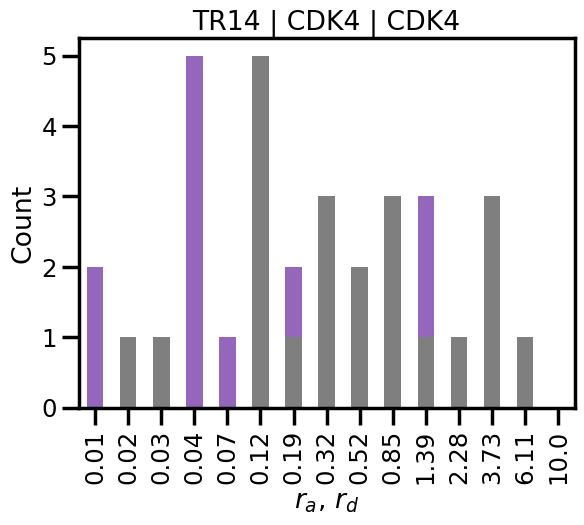

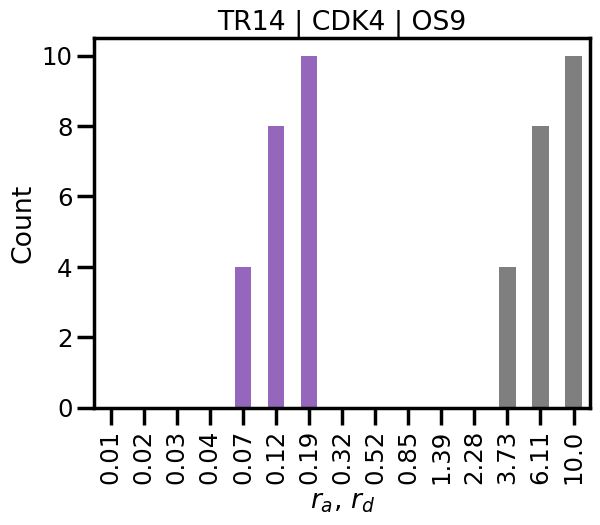

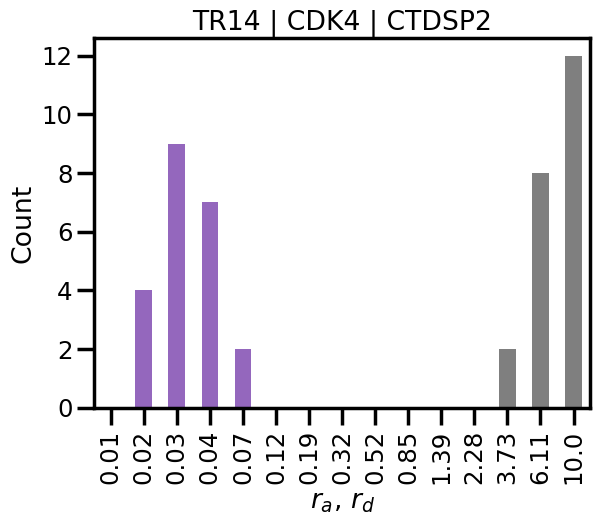

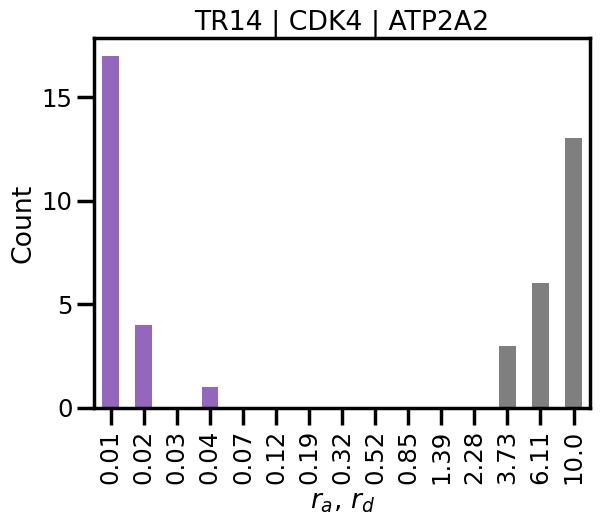

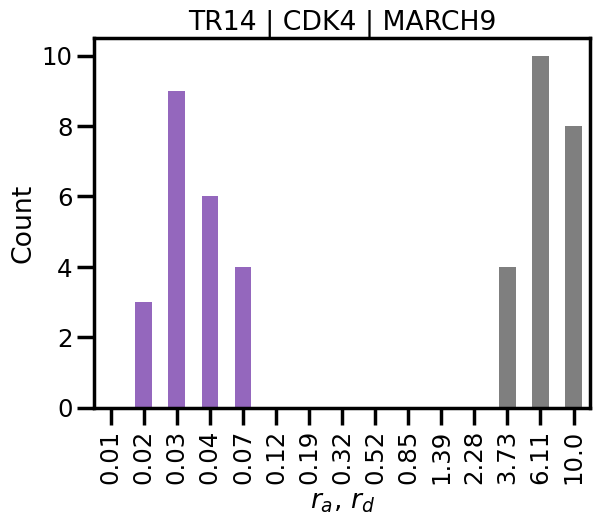

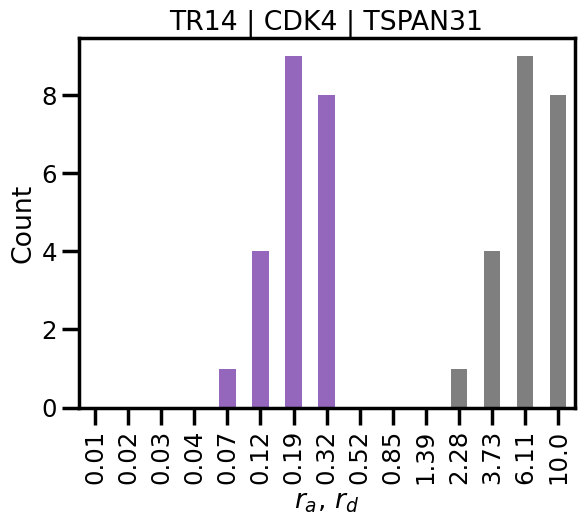

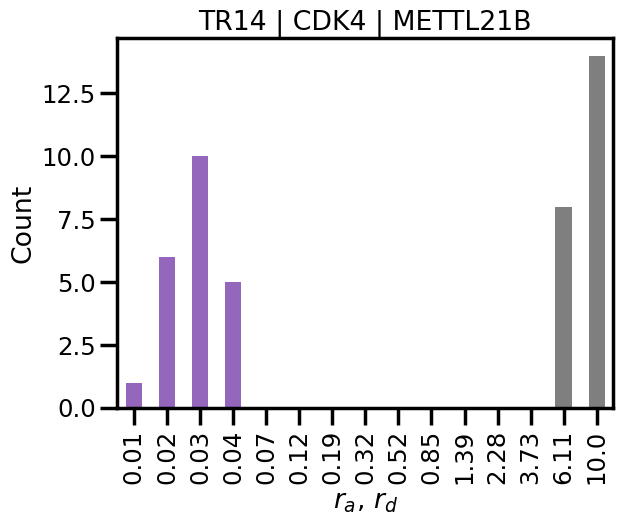

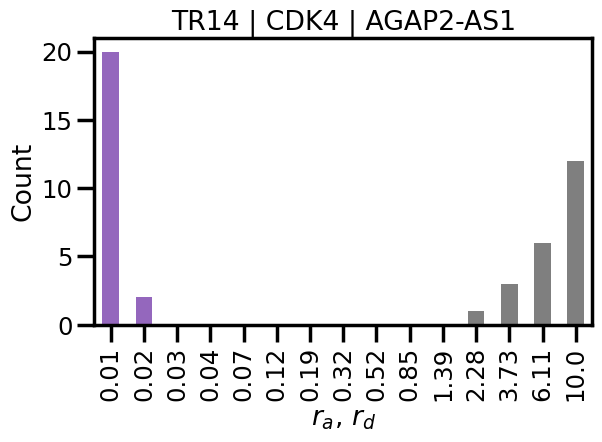

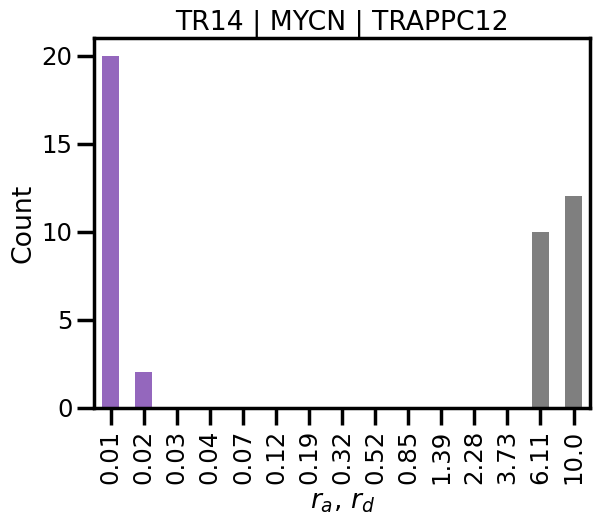

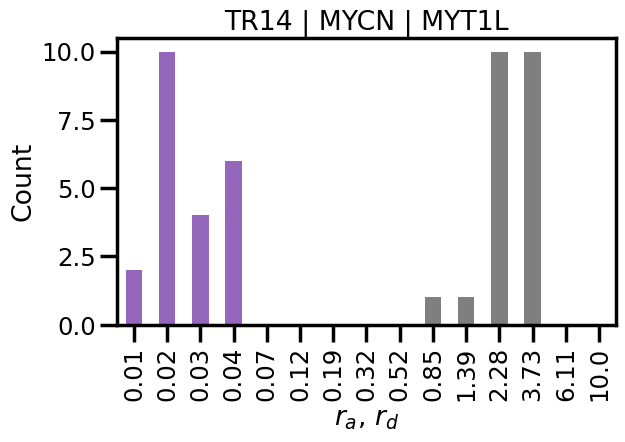

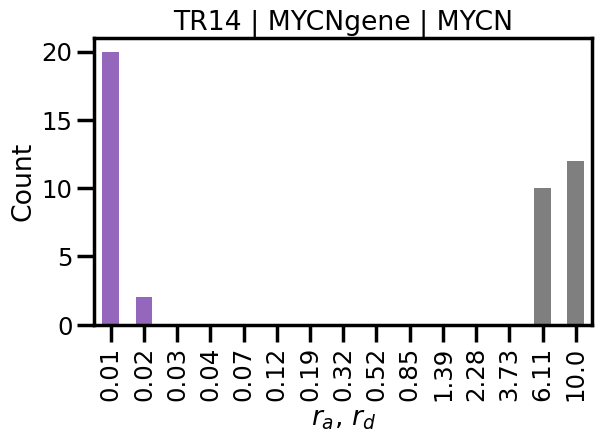

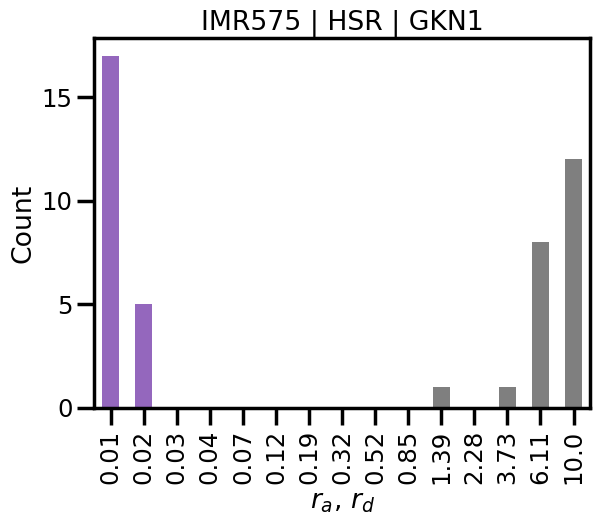

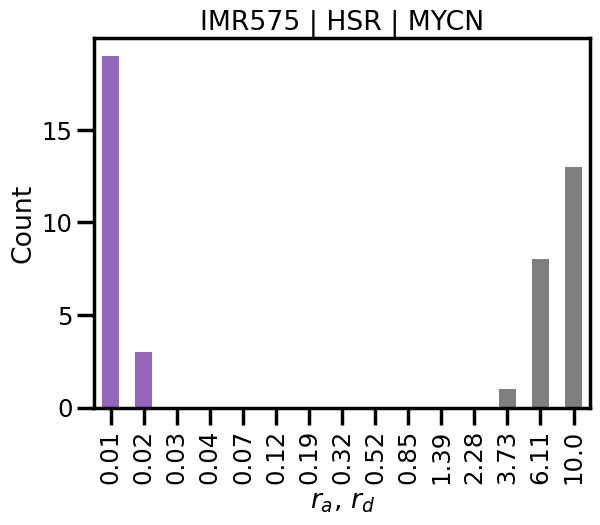

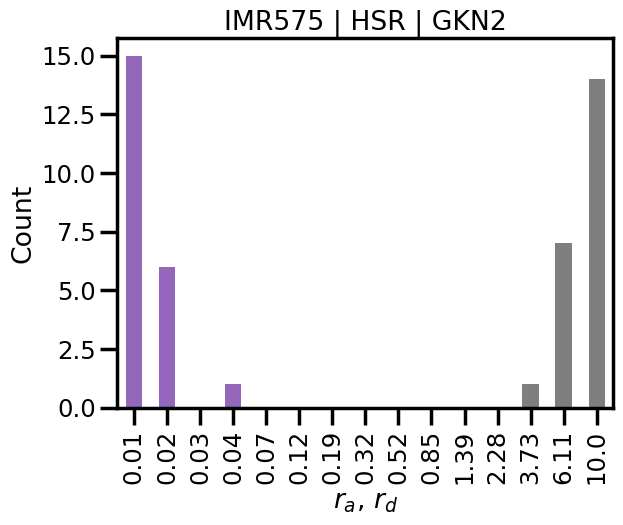

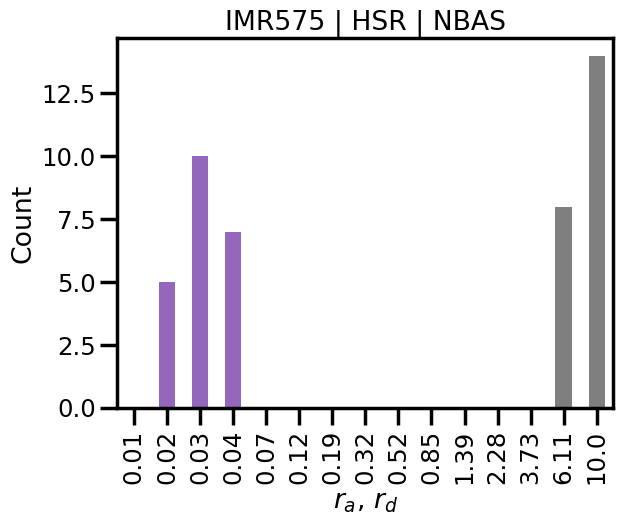

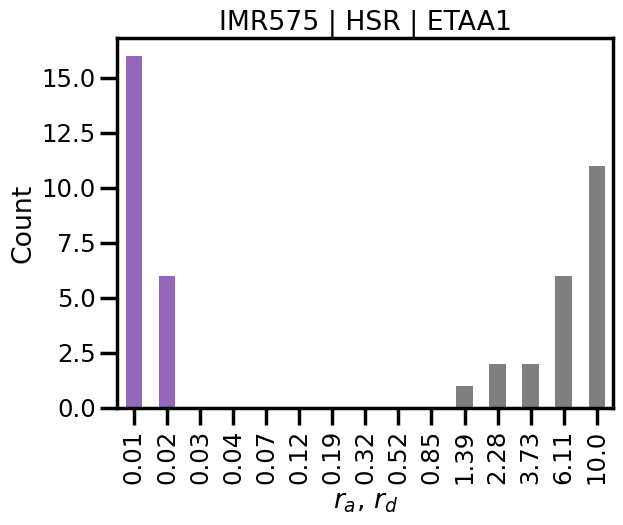

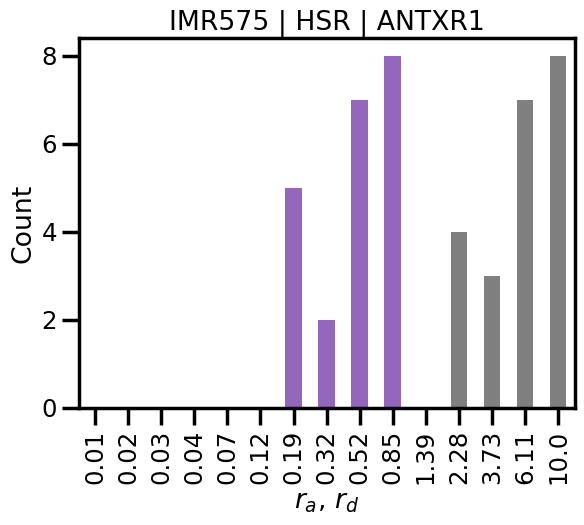

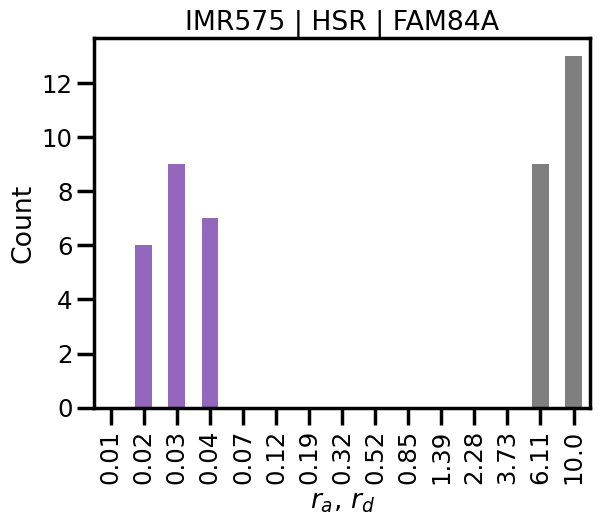

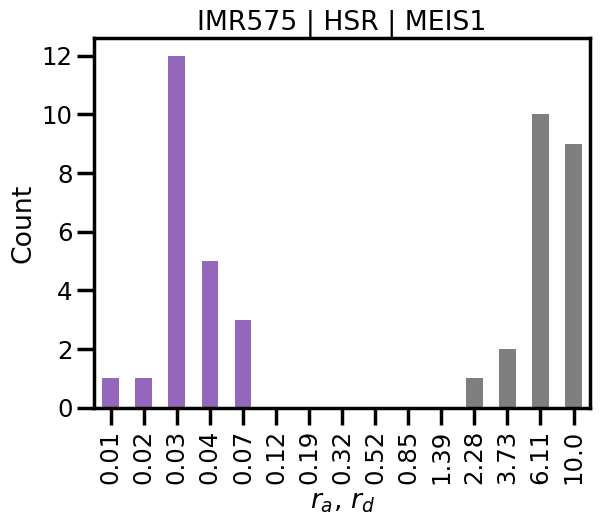

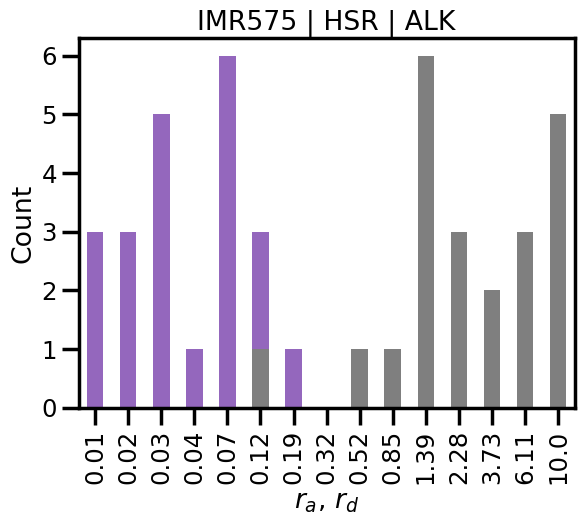

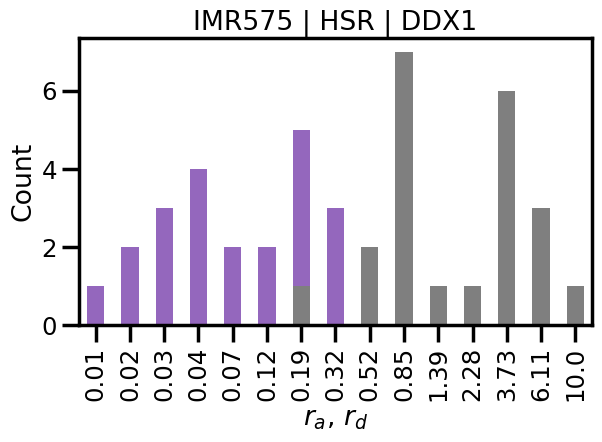

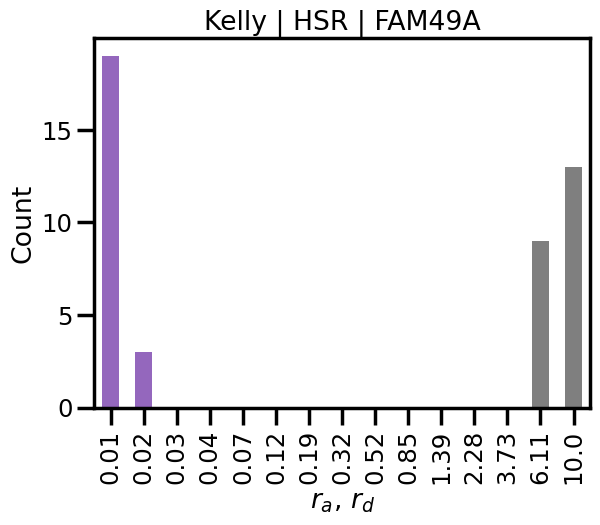

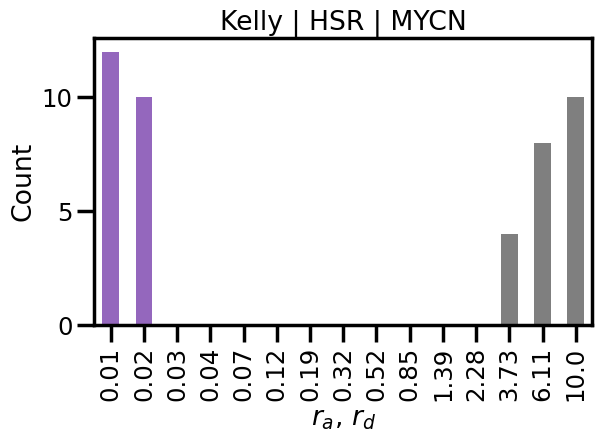

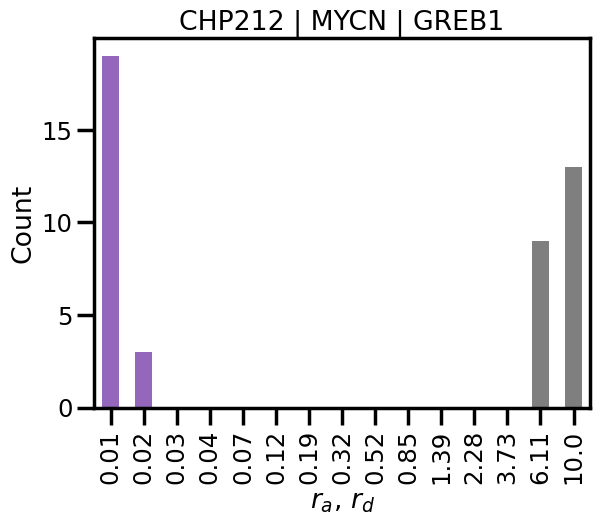

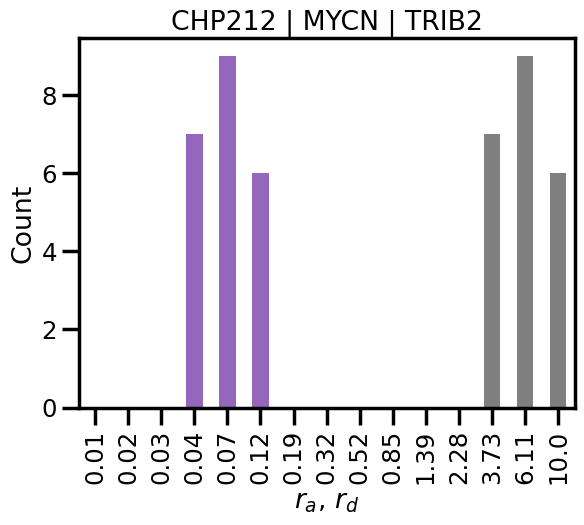

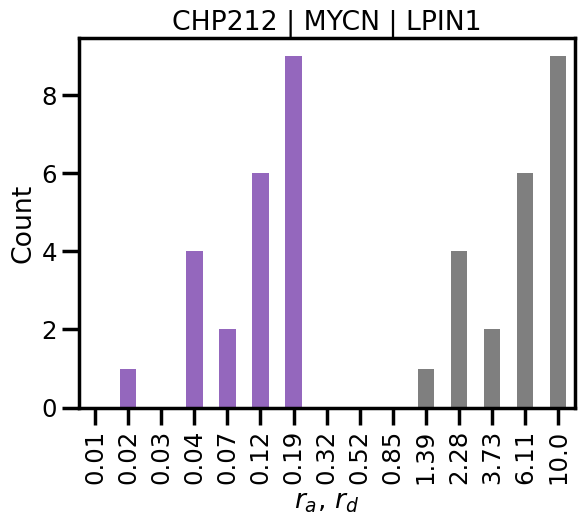

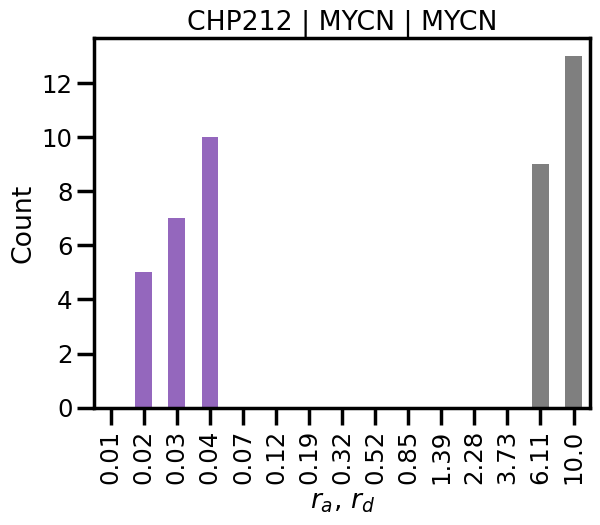

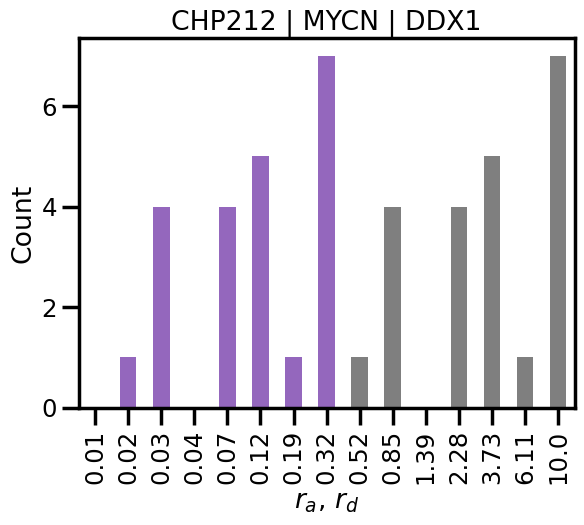

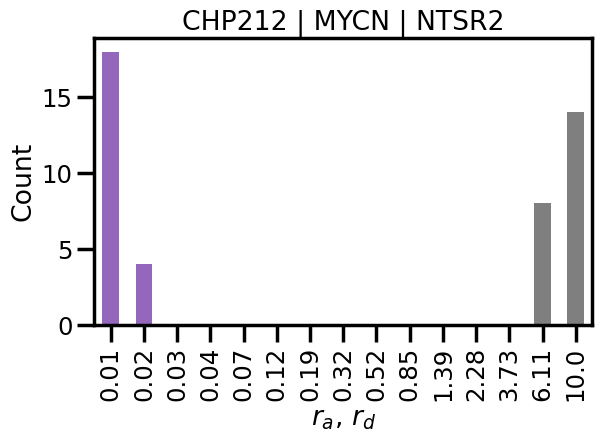

In [48]:
n_cell_lines = sim_df['cell_line'].unique().size
n_genes = sim_df['hgnc'].unique().size
for i,cell_line in enumerate(sim_df['cell_line'].unique()):
        for j,ampl in enumerate(sim_df[sim_df['cell_line']==cell_line]['amplicon'].unique()):
                for k,gene in enumerate(sim_df[(sim_df['cell_line']==cell_line) & (sim_df['amplicon']==ampl)]['hgnc'].unique()):
                    plt.figure()
                    pd.pivot_table(sim_df[(sim_df['cell_line']==cell_line) & (sim_df['hgnc']==gene)], 
                                   values='accept',
                                   index='$k_a$',
                                   aggfunc='sum'
                                  ).unstack().plot(kind='bar', color='tab:purple',
                                                   xticks=None, 
                                                   logx=False, sharex=True, sharey=True, 
                                                   title=cell_line+' | '+ampl+' | '+gene)
                    pd.pivot_table(sim_df[(sim_df['cell_line']==cell_line) & (sim_df['hgnc']==gene)], 
                                   values='accept',
                                   index='$k_d$',
                                   aggfunc='sum'
                                  ).unstack().plot(kind='bar', color='tab:gray', 
                                                   xticks=None,
                                                   logx=False, sharex=True, sharey=True, 
                                                   title=cell_line+' | '+ampl+' | '+gene)
                    tick_positions = [0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0]
                    plt.xticks(ticks=tick_positions,
                               labels=['0.01','0.02','0.03','0.04','0.07','0.12','0.19','0.32','0.52','0.85', '1.39','2.28','3.73','6.11','10.0'])
                    # plt.xticks([])
                    plt.xlabel('$r_a$, $r_d$')
                    plt.ylabel('Count')

                plt.tight_layout()

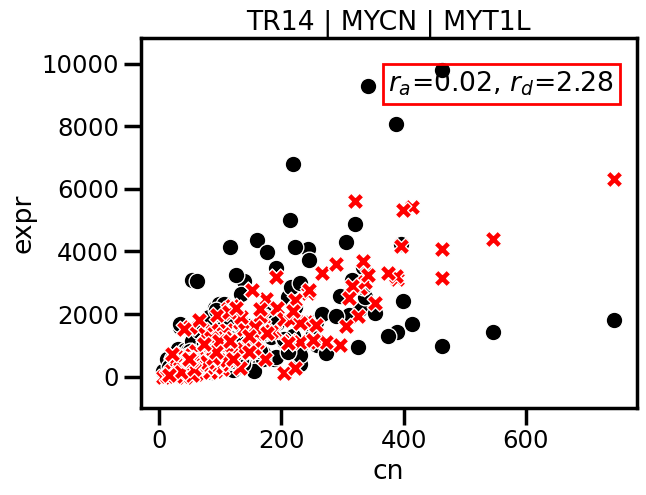

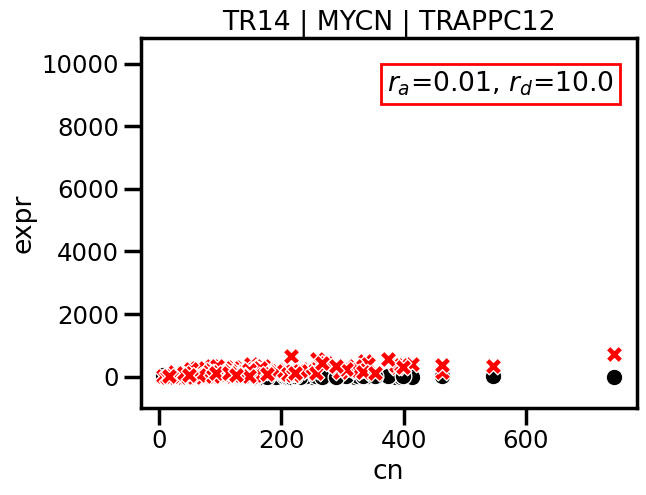

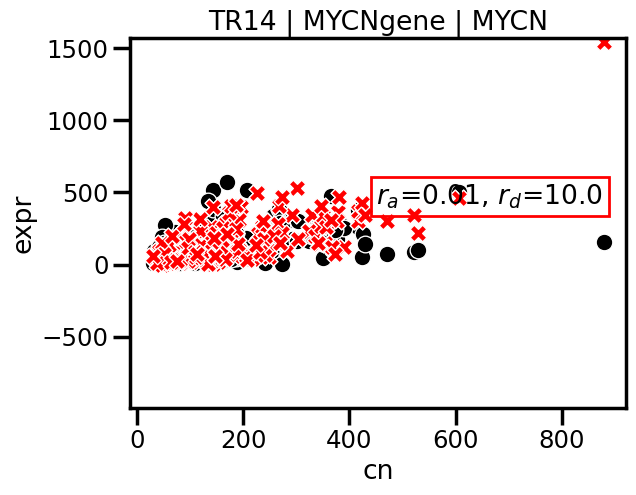

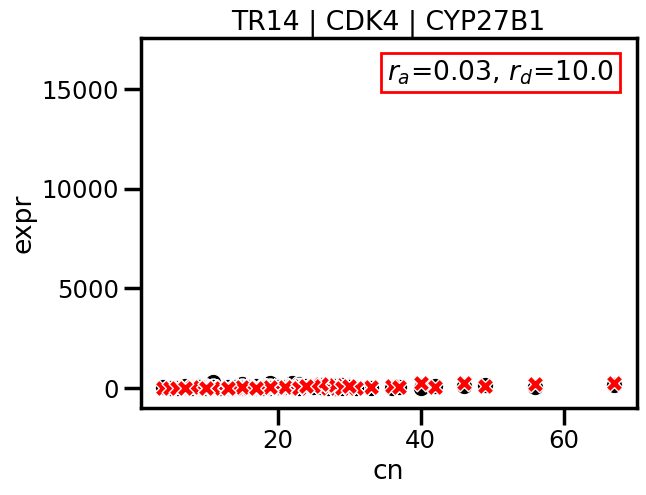

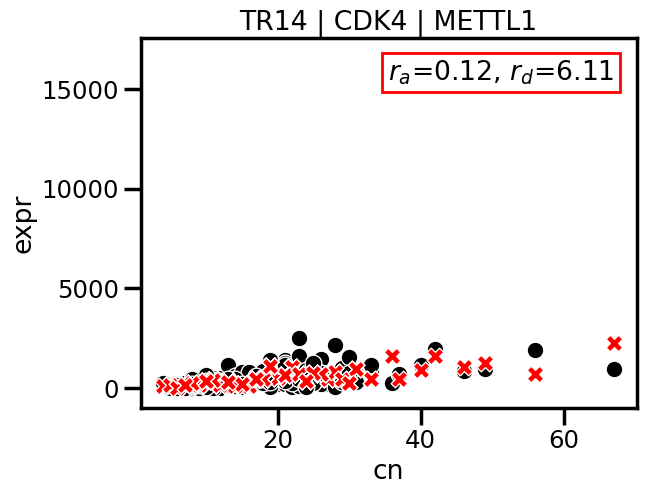

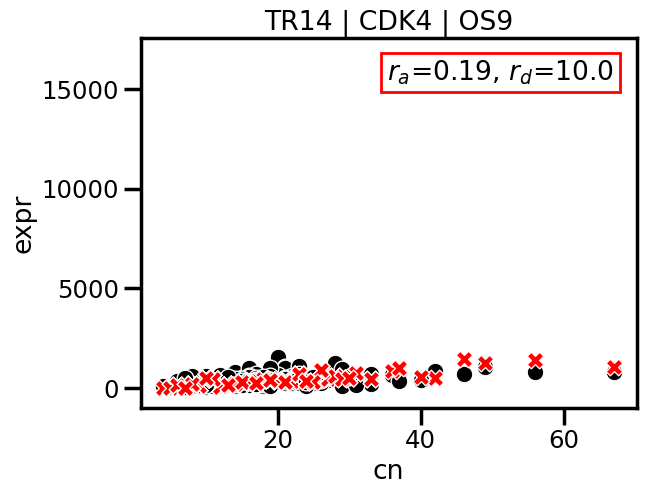

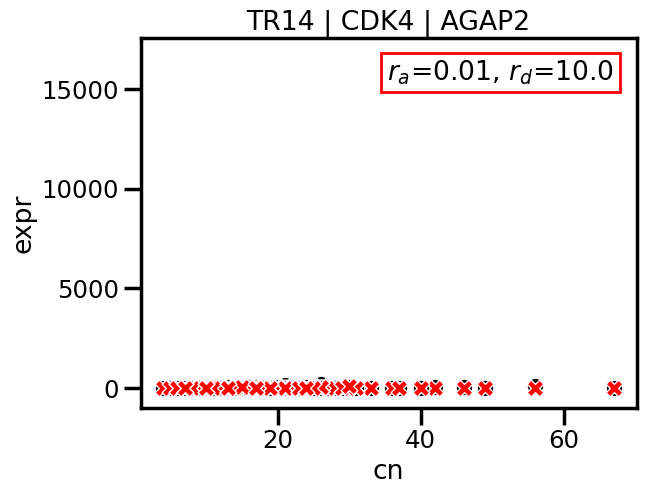

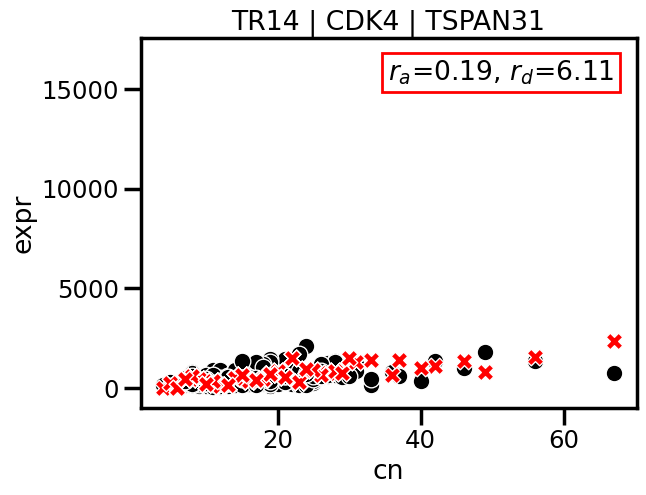

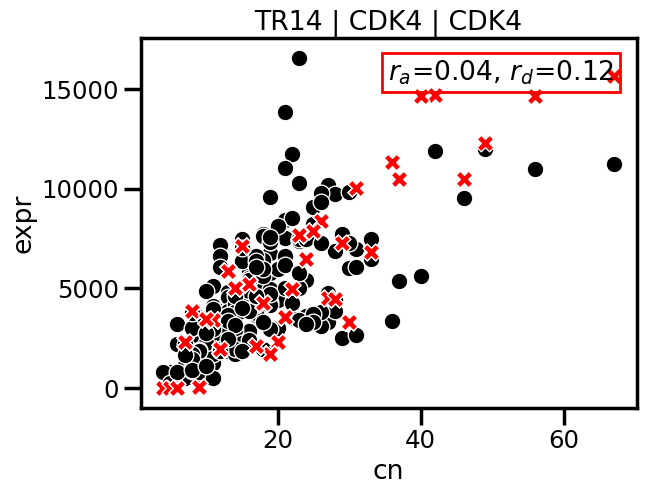

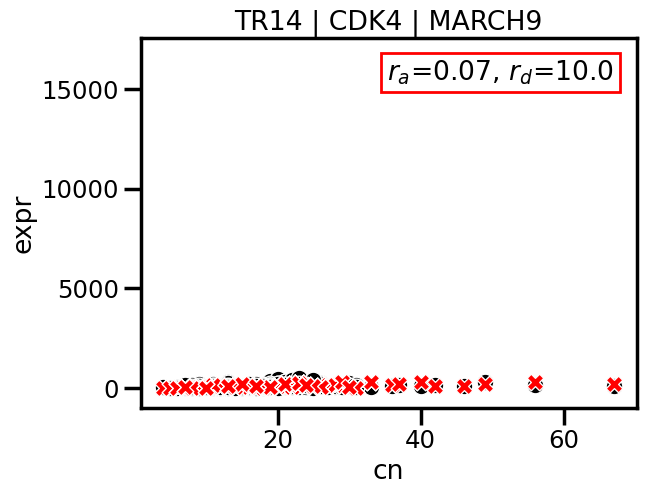

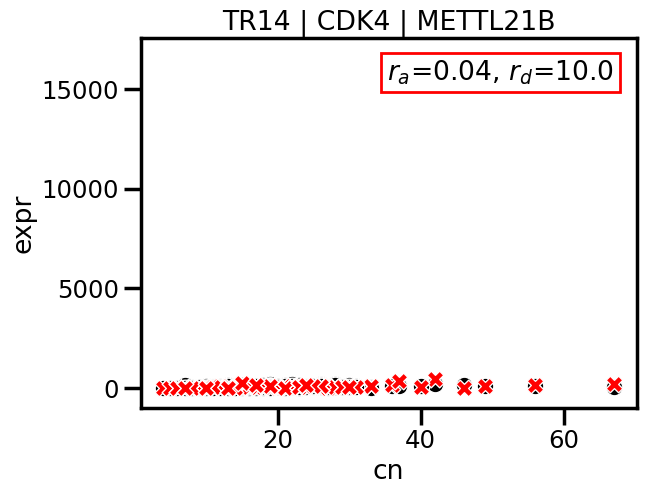

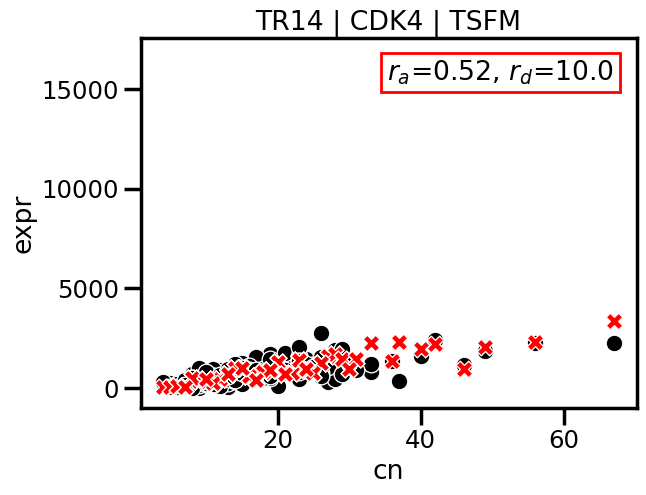

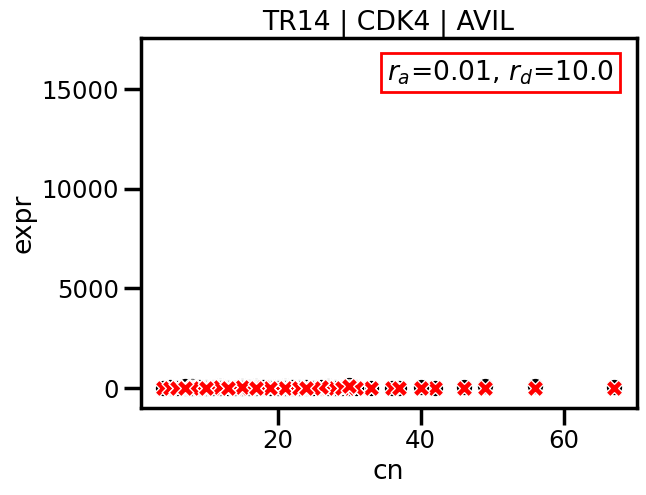

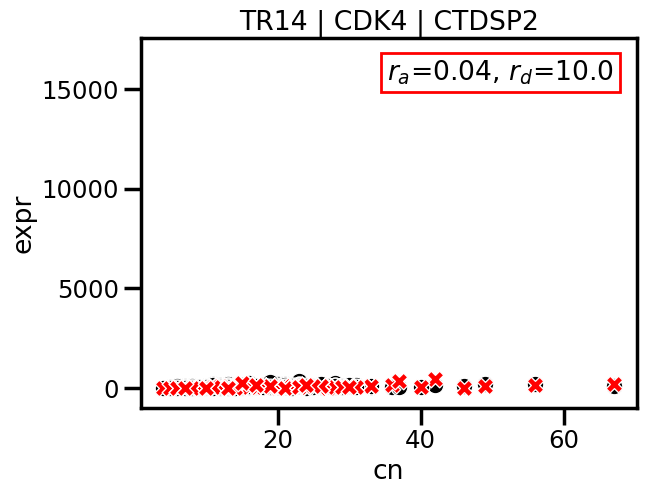

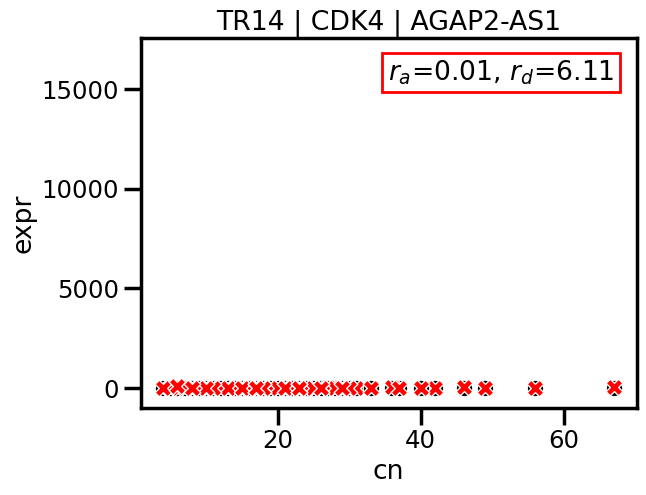

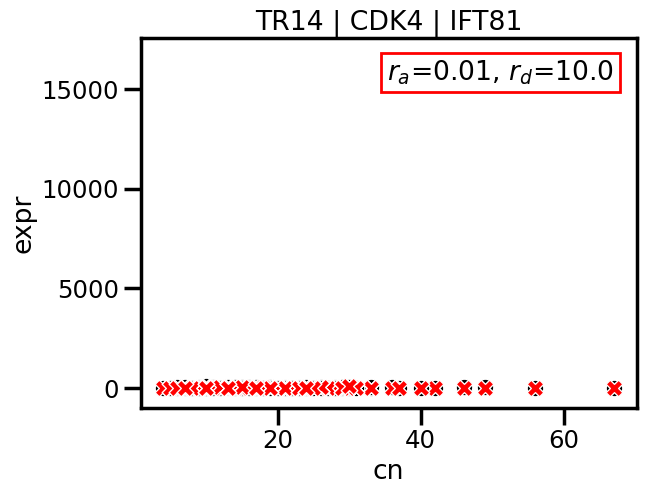

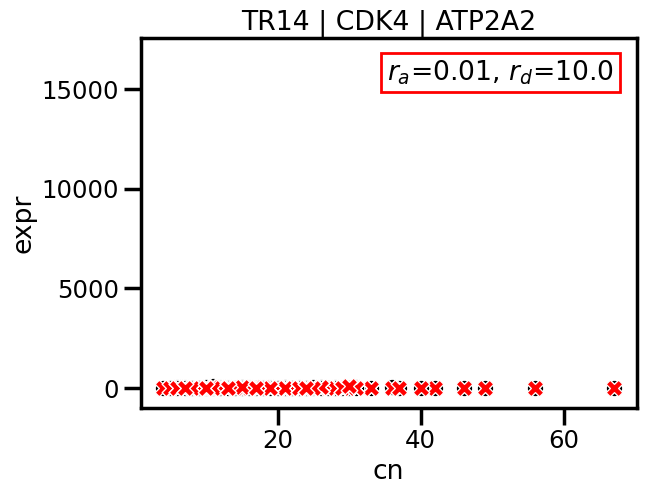

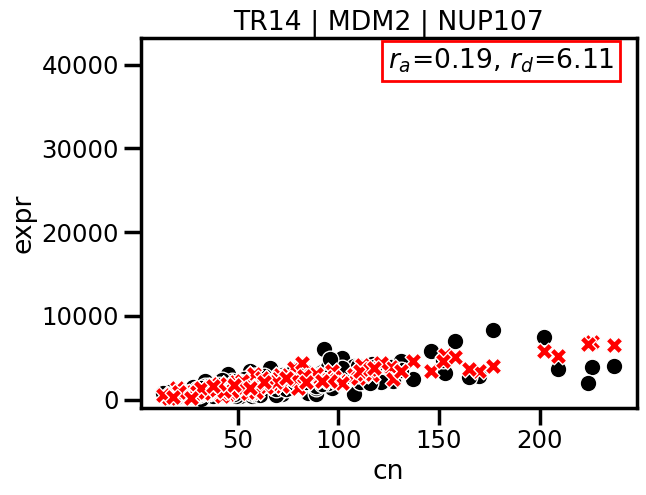

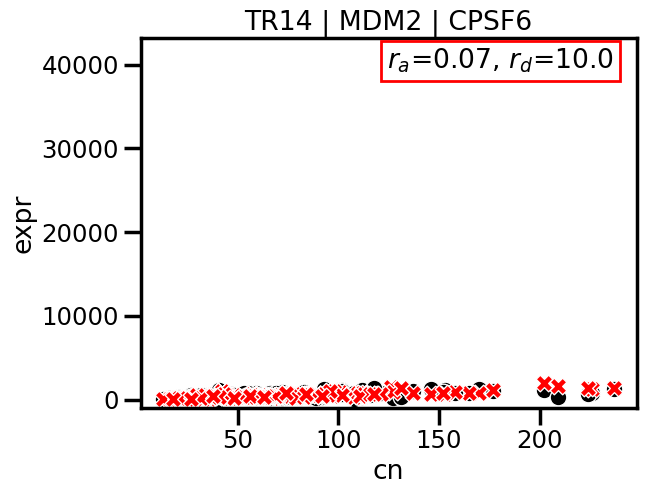

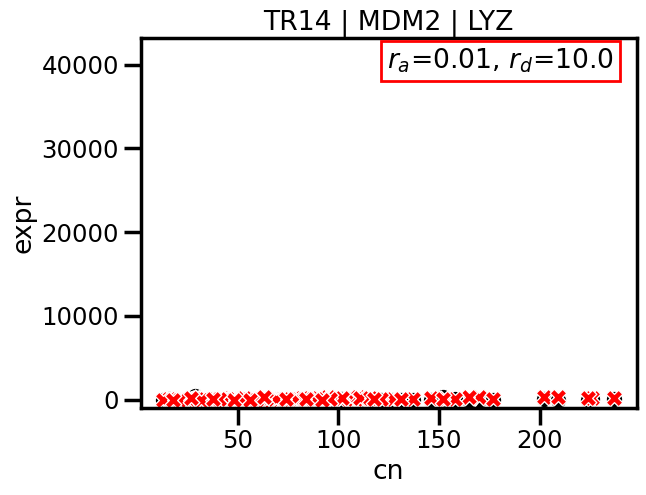

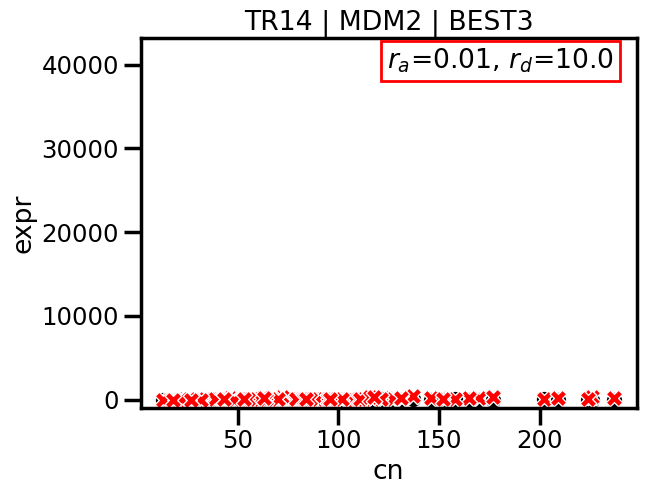

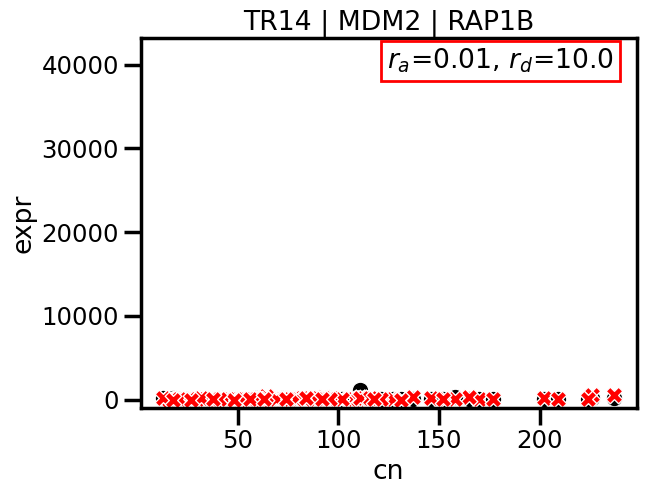

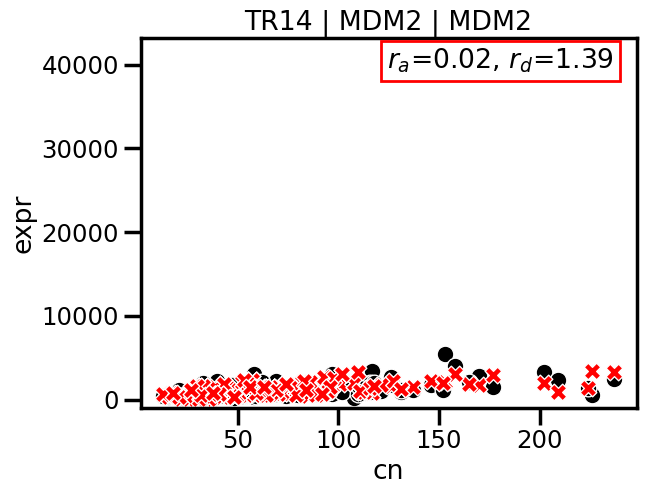

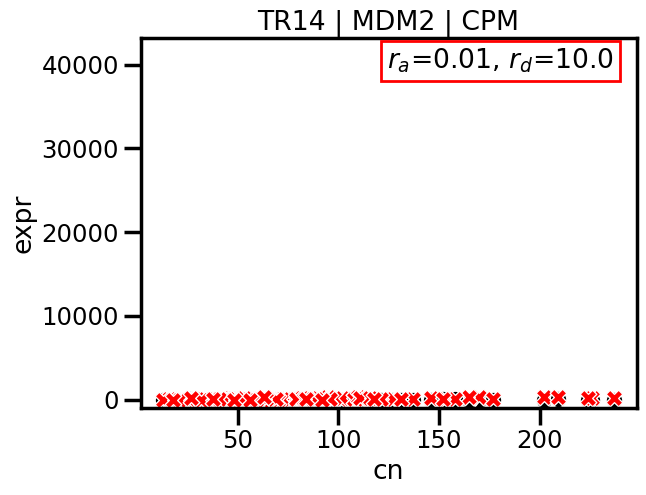

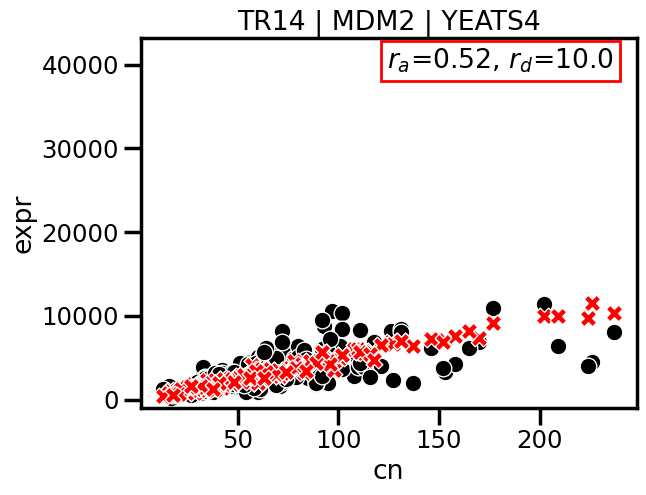

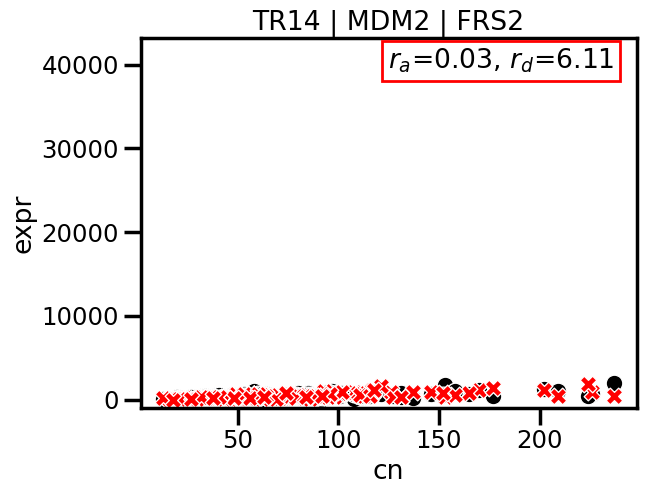

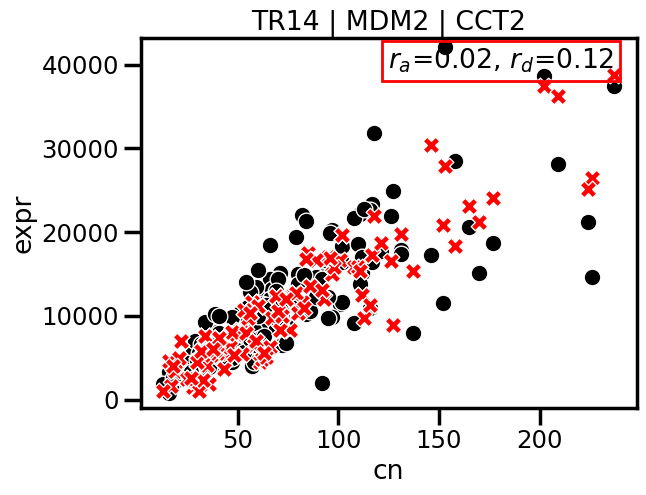

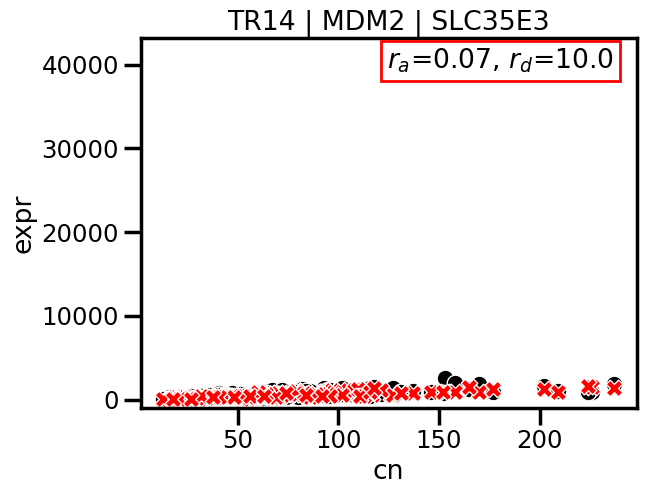

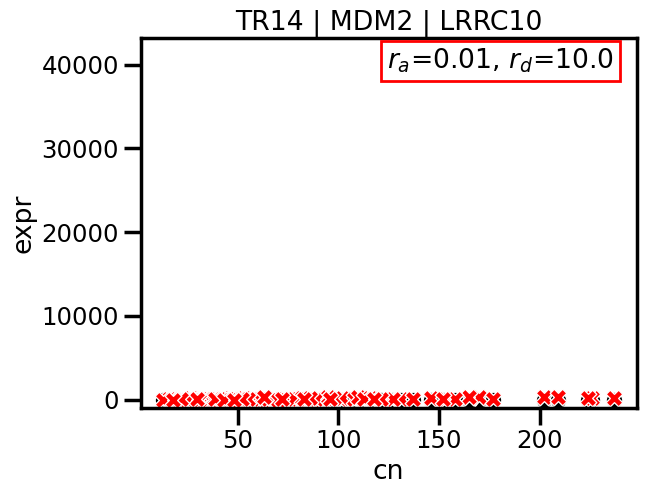

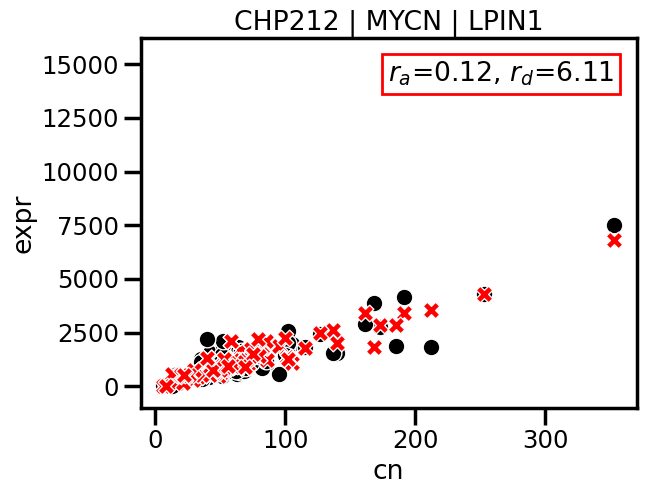

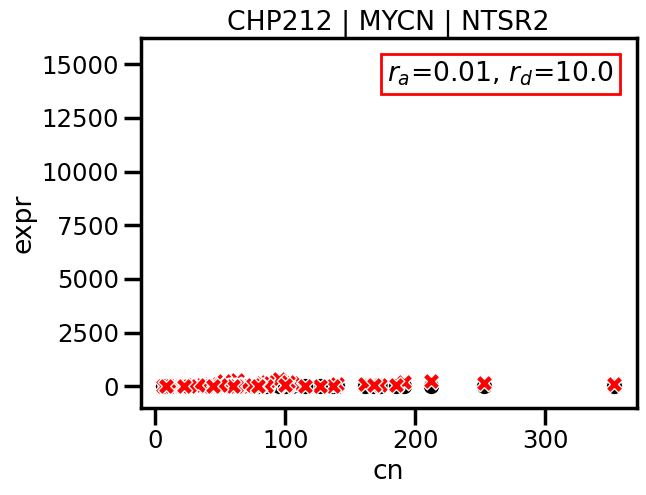

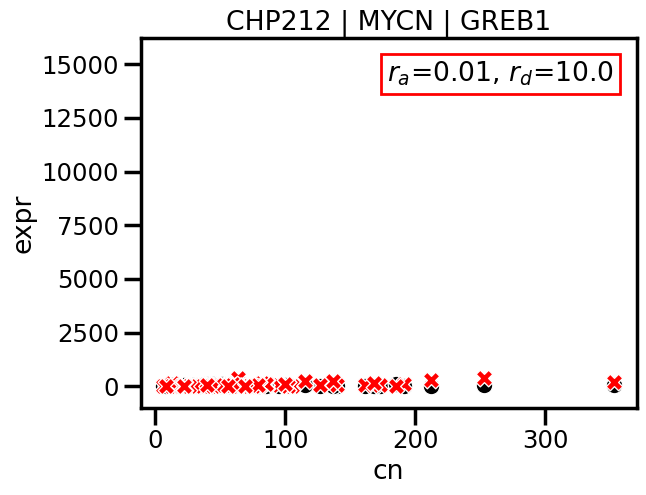

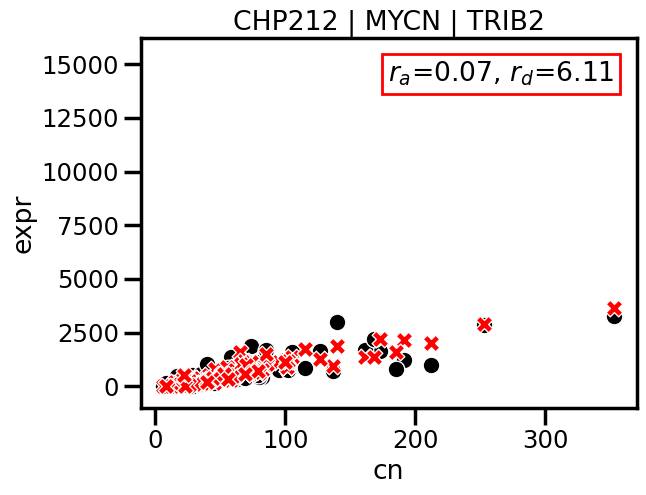

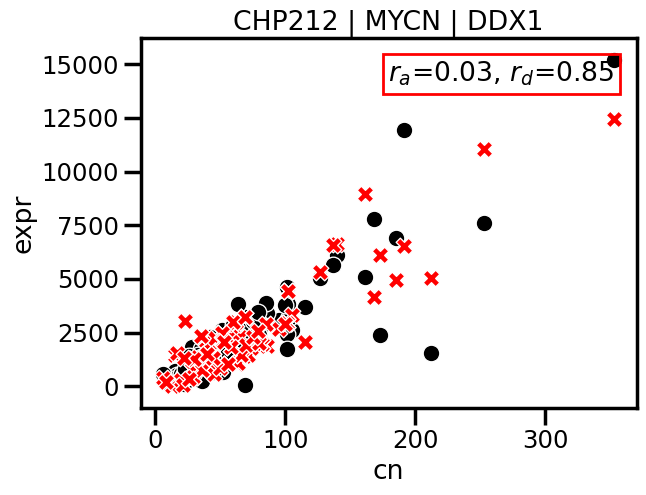

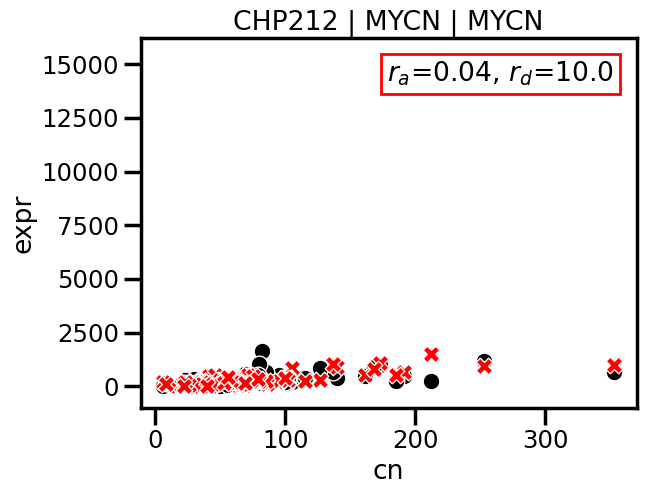

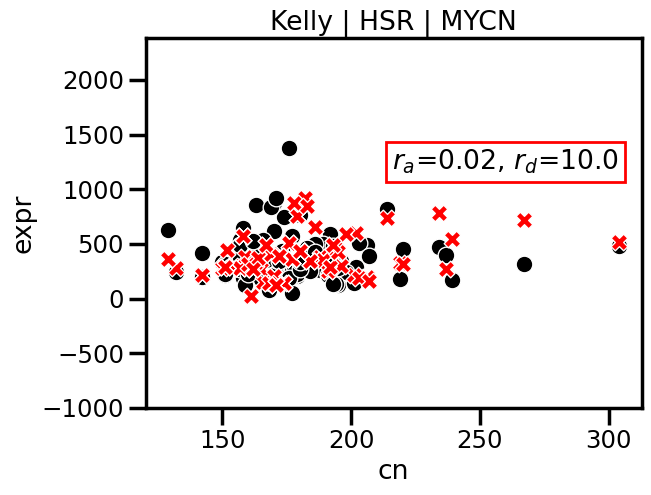

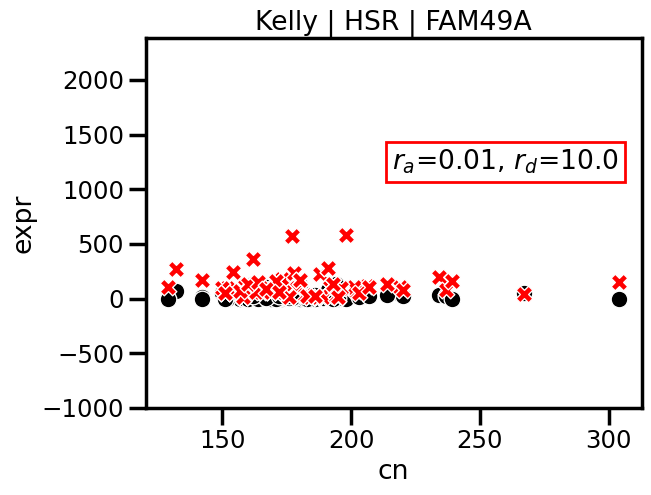

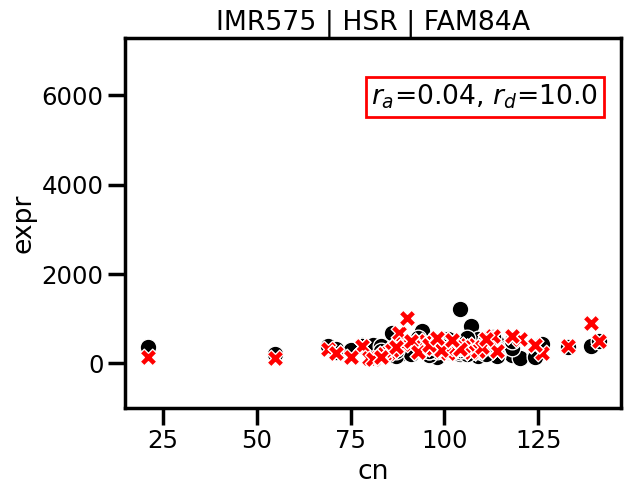

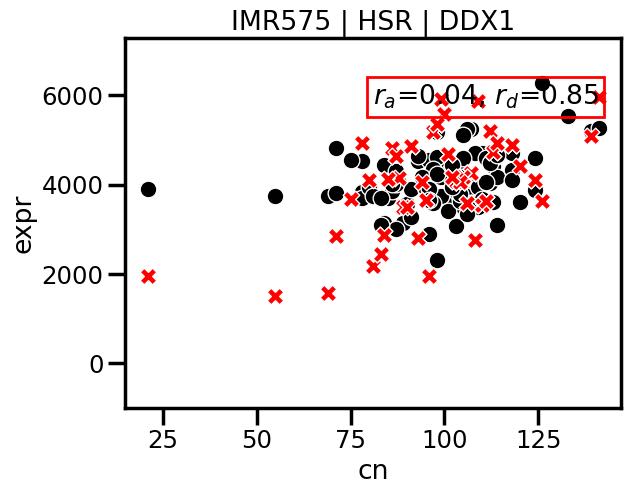

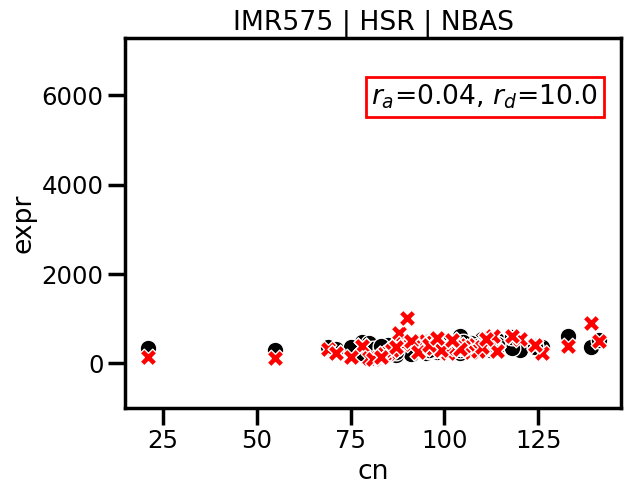

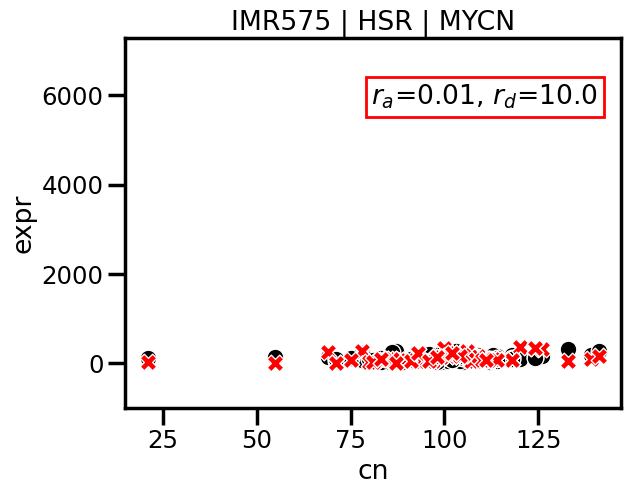

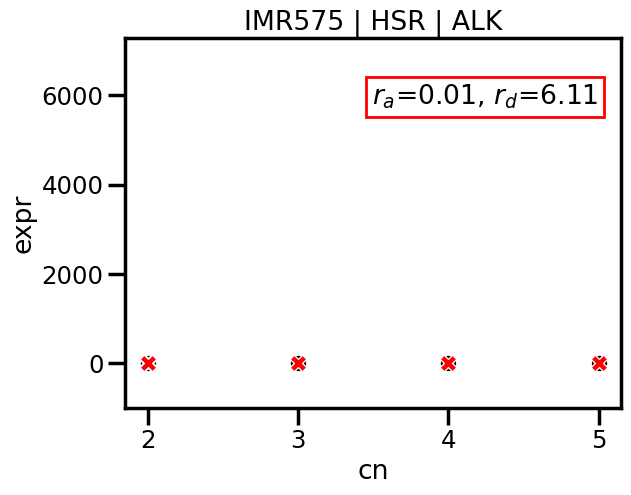

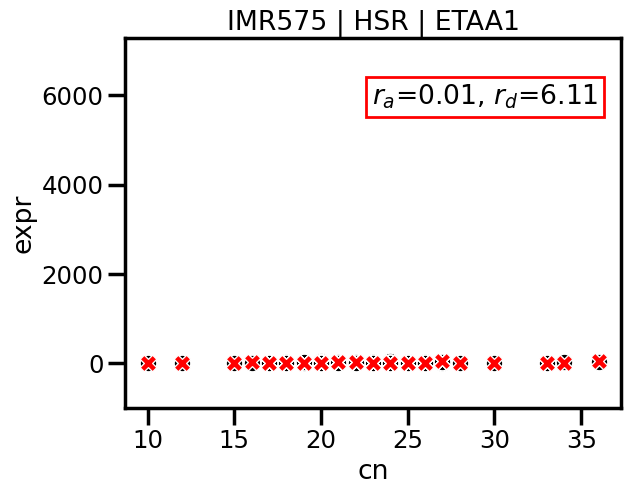

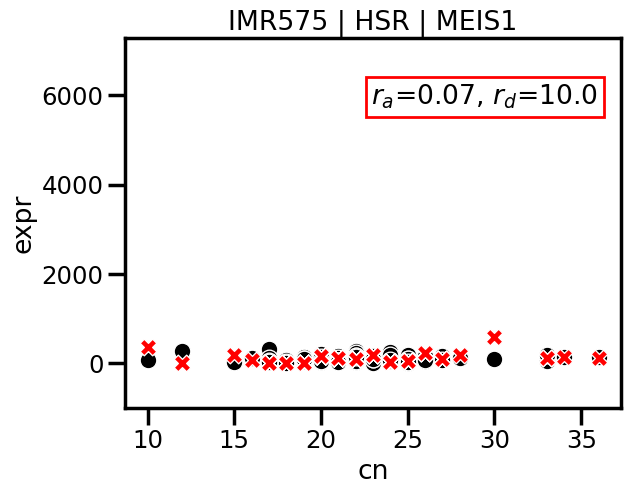

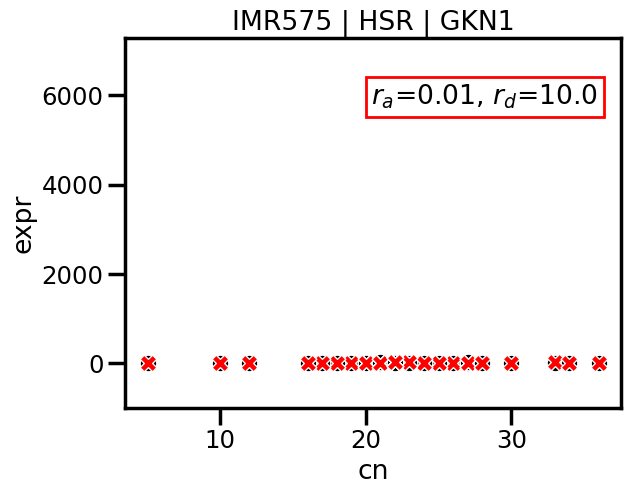

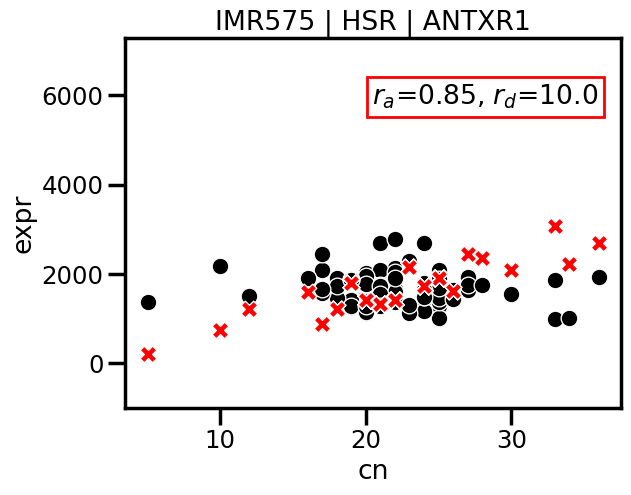

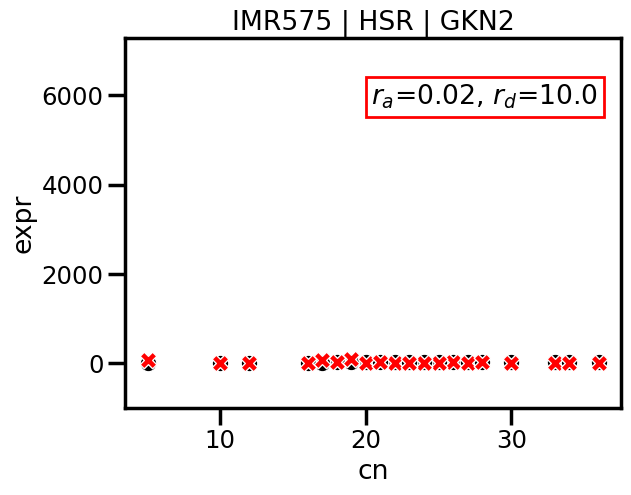

In [49]:
n_cell_lines = sim_df['cell_line'].unique().size
n_genes = sim_df['hgnc'].unique().size
bestfits = []
for i,combination in enumerate(exp_df[['cell_line', 'amplicon', 'hgnc']].drop_duplicates().values):
    cell_line, ampl, gene = combination
    data_bf = sim_df[(sim_df['cell_line']==cell_line) & (sim_df['amplicon']==ampl) & (sim_df['hgnc']==gene)].sort_values('Wasserstein distance').iloc[0]
    bestfits.append((data_bf['cell_line'],data_bf['amplicon'],data_bf['hgnc'],str(data_bf['$k_a$']),
                     str(data_bf['$k_d$'])))
    data_bf_lims = exp_df[(exp_df['cell_line']==cell_line) & (exp_df['amplicon']==ampl)]
    plt.figure()
    data_select = exp_df[(exp_df['cell_line']==cell_line) & (exp_df['amplicon']==ampl) & (exp_df['hgnc']==gene)]
    s1 = sns.scatterplot(data=data_select, x='cn', y='expr', c='k', legend=False)
    s1.set_ylim(data_bf_lims['expr'].values.min()-1000, data_bf_lims['expr'].values.max()+1000)
    plt.title(cell_line+' | '+ampl+' | '+gene)
    plt.text(data_select['cn'].values.max(), data_bf_lims['expr'].values.max(), 
             '$r_a$='+str(data_bf['$k_a$'])+', $r_d$='+str(data_bf['$k_d$']), 
             ha='right', va='top',
             bbox=dict(edgecolor='r', facecolor='none'))#+', traj='+str(data_bf['trajectory'])+')')
    sns.scatterplot(data=data_bf, x='cn', y='expr', legend=False, color='r', marker='X', alpha=1)
    plt.ylim(data_bf_lims['expr'].values.min()-1000, data_bf_lims['expr'].values.max()+1000)

## Prediction of cell types following genotoxic therapy 

We modelled genotoxic therapy using the framework in [Montuori and Tu's paper](https://aacrjournals.org/cancerdiscovery/article/15/10/2054/765955/Extrachromosomal-DNA-Driven-Oncogene-Dosage). In this model, a cell with greater ecDNA copy numbers is more likely to die as a result of genotoxic therapy.

In [56]:
from scipy.special import comb
def cn_dep_fitness(no_ecdna, cn_e=15, cn_m=4):
    """
    Function that outputs value of copy-number-dependent fitness
    no_ecdna (int): total number of ecDNA in cell
    cn_e (int), cn_m (int): thresholds that determine shape of fitness function (default 15, 4)
    
    """
    if no_ecdna < cn_e:
        fitness = (1.0 + (cn_e - no_ecdna)/(cn_e - cn_m))*((no_ecdna/cn_e)**(cn_e/(cn_e-cn_m)))
    else:
        fitness = 1.0
    return fitness
    
def prob_cell_death(no_ecdna, no_ecdna_thresh=10, p=0.5, const_fitness=False):
    """
    Function that outputs probability of a cell being killed by chemotherapy as a result of ecDNA damage
    no_ecdna (int) : total number of ecDNA in cell
    no_ecdna_thresh (int): number of ecDNA that need to be damaged for a cell to undergo apoptosis (default 10)
    p (double): probability that an ecDNA is damaged by chemotherapy (default 0.5)
    const_fitness (bool): external fitness function is called if false (default False)
    
    """
    # No. of ecDNA damaged is given by the cumulative distribution of a binomial distribution
    cumulative = 0
    for k in range(no_ecdna_thresh,no_ecdna,1): cumulative += comb(no_ecdna, k)*(p**k)*((1-p)**(no_ecdna-k))
    if not const_fitness: 
        cumulative = cn_dep_fitness(no_ecdna)*cumulative
    return cumulative        

def compute_pmf(counts, bins, average=False, avg=1000):
    if average: counts = counts/avg
    hist, bin_edges = np.histogram(counts,bins=bins)
    pmf = hist/hist.sum()
    return hist, bin_edges

In [66]:
def plot_joint_plot_after_therapy_2(ecdna_file, mrna_file, ecdna_file_runs=100):
    # load txt file containing ecDNA counts
    ecdna_counts = np.loadtxt(ecdna_file)
    # upto first 100 runs
    ecdna_counts_flat = ecdna_counts[:ecdna_file_runs].flatten()
    # only take cells with a nonzero count of ecDNA
    ecdna_counts_nonzero = ecdna_counts_flat[ecdna_counts_flat!=0].astype('int')
    # mrna counts
    mrna_counts = np.loadtxt(mrna_file).astype('int')
    
    # Kill cells according to copy-number-dependent cell death probability
    np.random.seed(0)
    rnd = np.random.uniform(0.0,1.0,ecdna_counts_nonzero.shape) # array of random numbers to decide cell death
    persisters = []
    dead = []
    med_ecdna = np.median(ecdna_counts_nonzero)
    med_mrna = np.median(mrna_counts)
    for i,cell in enumerate(zip(ecdna_counts_nonzero,mrna_counts)):
        p_cell_death = prob_cell_death(cell[0], no_ecdna_thresh=10, p=0.5)
        if rnd[i] < p_cell_death: 
            dead.append(cell)
        else:
            if cell[0]<=med_ecdna and cell[1]<=med_mrna:
                persisters.append((cell,'tab:red'))
            if cell[0]<=med_ecdna and cell[1]>med_mrna:
                persisters.append((cell,'m'))
            if cell[0]>med_ecdna and cell[1]<=med_mrna:
                persisters.append((cell,'tab:red'))
            if cell[0]>med_ecdna and cell[1]>med_mrna:
                persisters.append((cell,'y'))
    
    # assign facecolors to plot
    fc = []
    pers = []
    for p in persisters: 
        fc.append(p[-1])
        pers.append((p[0]))

    dead = np.array(dead)
    pers = np.array(pers)

    # compute & plot marginals
    bin_size_ecdna = 1
    bin_size_mrna = 1000
    ecdna_hist, bin_edges = np.histogram(ecdna_counts_nonzero,
                                     bins=np.arange(0,
                                                    ecdna_counts_nonzero.max()+bin_size_ecdna+1,
                                                    bin_size_ecdna))
    mrna_counts_hist, bin_edges_counts = np.histogram(mrna_counts,
                                         bins=np.arange(0,
                                                        mrna_counts.max()+bin_size_mrna+1,
                                                        bin_size_mrna/20))
    pers_ecdna_pmf = compute_pmf(pers[:,0], np.arange(0,ecdna_counts_nonzero.max()+bin_size_ecdna+1,
                                                              bin_size_ecdna))[0]
    pers_mrna_pmf = compute_pmf(pers[:,1], np.arange(0,mrna_counts.max()+bin_size_mrna+1,
                                                              bin_size_mrna/20))[0]

    fig, ax1 = plt.subplots()
    ax2 = fig.add_axes([0.15, 0.55, 0.3, 0.3])
    ax2.patch.set_alpha(0.5)

    ax1.scatter(dead[:,0], dead[:,1], marker='x', s=10, color='k', alpha=0.01)
    ax1.scatter(pers[:,0], pers[:,1], facecolors=fc, s=10, edgecolors='none', alpha=0.4)
    ax1.axhline(y=med_mrna, color='k', linestyle='--')#, label='Median mRNA')
    ax1.axvline(x=med_ecdna, color='k', linestyle='-.')#, label='Median ecDNA')
    ax1.set_ylabel('mRNA copy number')
    ax1.set_xlabel('ecDNA copy number')
    ax1.set_ylim(-2000, 70000)
    ax1.set_xlim(-4, 78)
    
    ax2.plot(range(6)[::-1], color='green')
    ax2.bar(bin_edges_counts[:-1], mrna_counts_hist, align='edge',
               fill=True, ec='k', alpha=0.1, facecolor='k', label='ecDNA')
    ax2.bar(bin_edges_counts[:-1], pers_mrna_pmf, align='edge',
               fill=True, ec='tab:orange', alpha=0.2, facecolor='orange', label='ecDNA targeting')
    ax2.tick_params("both", rotation=45, labelsize=11)
    ax2.yaxis.set_label_position("right")
    ax2.yaxis.tick_right()
    plt.show()
    return None

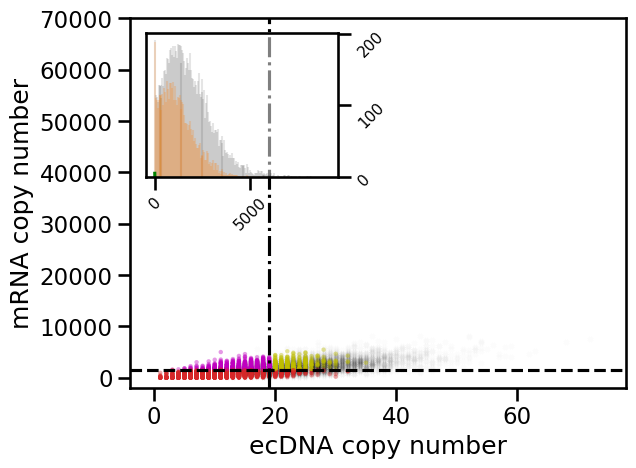

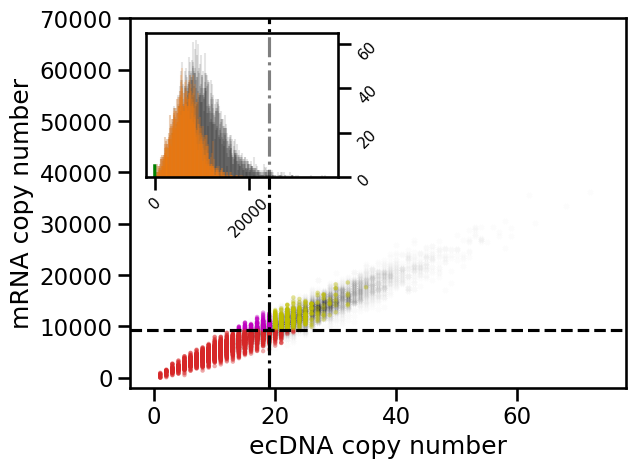

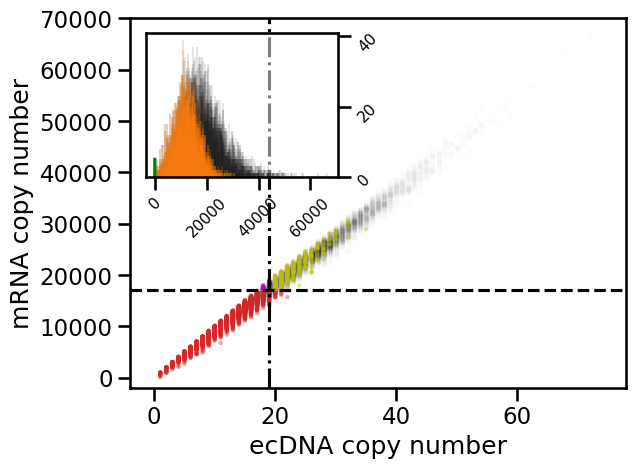

In [67]:
ecdna_file = './simulated_ecdna_data/Summary_3_20.txt'
mrna_dir = './simulated_ecdna_data/mrna_dists/'
mrna_prefix = 'mrna_3_20_'
mrna_suffix = '_1000_1.txt'
mrna_filenames = ['01_1', '1_1', '1_01']
mrna_files = [mrna_dir+mrna_prefix+file+mrna_suffix for file in mrna_filenames]
ka_kd = ['$k_a$='+file.split('_')[0]+', $k_d$='+file.split('_')[1] for file in mrna_filenames]
for mrna_file in mrna_files[:-1]: plot_joint_plot_after_therapy_2(ecdna_file, mrna_file)
plot_joint_plot_after_therapy_2(ecdna_file, mrna_files[-1])

In [70]:
def plot_cell_fractions(ecdna_file, mrna_dir, output_file):
    # load txt file containing ecDNA counts
    ecdna_counts = np.loadtxt(ecdna_file)
    # upto first 100 runs
    ecdna_counts_flat = ecdna_counts[:100].flatten()
    # only take cells with a nonzero count of ecDNA
    ecdna_counts_nonzero = ecdna_counts_flat[ecdna_counts_flat!=0].astype('int')
    mrna_dist_files = (file for file in sorted(os.listdir(mrna_dir)) 
                       if os.path.isfile(os.path.join(mrna_dir, file)) and file.startswith('mrna') and file.endswith('txt'))

    with open(output_file, 'w+') as file:
        for mrna_file in mrna_dist_files:
            print(mrna_file)
            # mrna counts
            mrna_counts = np.loadtxt(os.path.join(mrna_dir,mrna_file)).astype('int')
            
            # Kill cells according to copy-number-dependent cell death probability
            np.random.seed(0)
            rnd = np.random.uniform(0.0,1.0,ecdna_counts_nonzero.shape) # array of random numbers to decide cell death
            persisters = []
            dead = []
            med_ecdna = np.median(ecdna_counts_nonzero)
            med_mrna = np.median(mrna_counts)
            for i,cell in enumerate(zip(ecdna_counts_nonzero,mrna_counts)):
                p_cell_death = prob_cell_death(cell[0], no_ecdna_thresh=10, p=0.5)
                if cell[0]<=med_ecdna and cell[1]<=med_mrna:
                    if rnd[i] < p_cell_death:
                        dead.append((cell, 'tab:red'))
                    else:
                        persisters.append((cell,'tab:red'))
                if cell[0]<=med_ecdna and cell[1]>med_mrna:
                    if rnd[i] < p_cell_death:
                        dead.append((cell, 'm'))
                    else:
                        persisters.append((cell,'m'))
                if cell[0]>med_ecdna and cell[1]<=med_mrna:
                    if rnd[i] < p_cell_death:
                        dead.append((cell, 'tab:red'))
                    else:
                        persisters.append((cell,'tab:red'))
                if cell[0]>med_ecdna and cell[1]>med_mrna:
                    if rnd[i] < p_cell_death:
                        dead.append((cell, 'y'))
                    else:
                        persisters.append((cell,'y'))
            
            rp = sum(p.count('tab:red') for p in persisters) # red persisters (low mrna)
            mp = sum(p.count('m') for p in persisters) # magenta persisters (high mrna, low ecdna)
            yp = sum(p.count('y') for p in persisters) # yellow persisters (high mrna, high ecdna)
            rd = sum(d.count('tab:red') for d in dead) # red dead
            md = sum(d.count('m') for d in dead) # magenta dead
            yd = sum(d.count('y') for d in dead) # yellow dead
        
            # compute cell fractions
            try:
                high_mrna_persisters = (yp+mp)/(yp+mp+yd+md)
            except ZeroDivisionError:
                high_mrna_persisters = np.inf
            try:
                low_ecdna_high_mrna_persisters = mp/(mp+yp+rp)
            except ZeroDivisionError:
                low_ecdna_high_mrna_persisters = np.inf
            fractions = [high_mrna_persisters, low_ecdna_high_mrna_persisters]
    
            # write ka and kd into file
            ka, kd = mrna_file.split('_')[3:5]
            if ka[0] == '0':
                if ka[1] == '0':
                    ka = float(ka)/100
                else:
                    ka = float(ka)/10
            else:
                ka = float(ka)
            if kd[0] == '0':
                if kd[1] == '0':
                    kd = float(kd)/100
                else:
                    kd = float(kd)/10
            else:
                kd = float(kd) 
            file.write(str(ka)+" "+str(kd)+" ")
            for val in fractions:
                file.write("%f " % val)
            file.write("\n")
            
    return None

In [71]:
ecdna_file = './simulated_ecdna_data/Summary_3_20.txt'
mrna_dir = './simulated_ecdna_data/mrna_dists/'
plot_cell_fractions(ecdna_file, mrna_dir, './simulated_ecdna_data/mrna_dists/fractions_treatment.txt')

mrna_3_20_001_001_1000_1.txt
mrna_3_20_001_003_1000_1.txt
mrna_3_20_001_005_1000_1.txt
mrna_3_20_001_007_1000_1.txt
mrna_3_20_001_009_1000_1.txt
mrna_3_20_001_01_1000_1.txt
mrna_3_20_001_03_1000_1.txt
mrna_3_20_001_05_1000_1.txt
mrna_3_20_001_07_1000_1.txt
mrna_3_20_001_09_1000_1.txt
mrna_3_20_001_1_1000_1.txt
mrna_3_20_001_3_1000_1.txt
mrna_3_20_001_5_1000_1.txt
mrna_3_20_001_7_1000_1.txt
mrna_3_20_001_9_1000_1.txt
mrna_3_20_003_001_1000_1.txt
mrna_3_20_003_003_1000_1.txt
mrna_3_20_003_005_1000_1.txt
mrna_3_20_003_007_1000_1.txt
mrna_3_20_003_009_1000_1.txt
mrna_3_20_003_01_1000_1.txt
mrna_3_20_003_03_1000_1.txt
mrna_3_20_003_05_1000_1.txt
mrna_3_20_003_07_1000_1.txt
mrna_3_20_003_09_1000_1.txt
mrna_3_20_003_1_1000_1.txt
mrna_3_20_003_3_1000_1.txt
mrna_3_20_003_5_1000_1.txt
mrna_3_20_003_7_1000_1.txt
mrna_3_20_003_9_1000_1.txt
mrna_3_20_005_001_1000_1.txt
mrna_3_20_005_003_1000_1.txt
mrna_3_20_005_005_1000_1.txt
mrna_3_20_005_007_1000_1.txt
mrna_3_20_005_009_1000_1.txt
mrna_3_20_005_0

(0.01, 10)

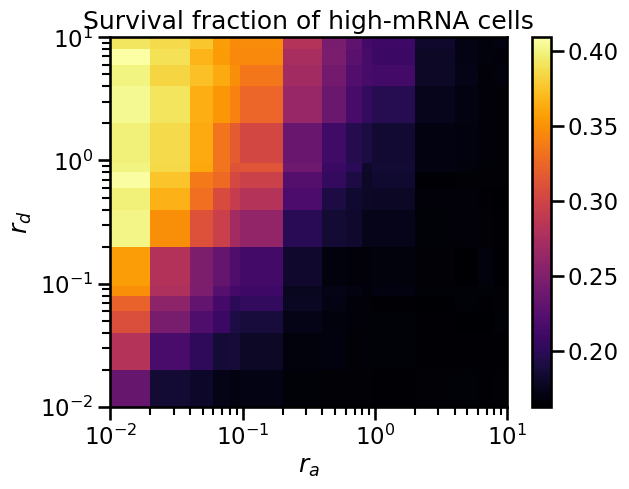

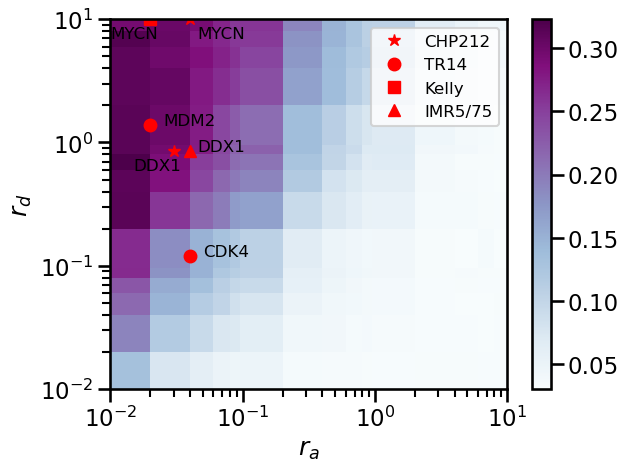

In [72]:
sns.set_context('talk', font_scale=1.0)
import matplotlib as mpl
fractions = np.loadtxt('./simulated_ecdna_data/mrna_dists/fractions_treatment.txt')
ra = fractions[:,0].reshape([15,15])
rd = fractions[:,1].reshape([15,15])
high_mrna_persisters = fractions[:,2].reshape([15,15])
low_ecdna_high_mrna_persisters = fractions[:,3].reshape([15,15])

plt.figure()
plt.pcolormesh(ra, rd, high_mrna_persisters, cmap='inferno')
plt.colorbar()
plt.xlabel('$r_a$')
plt.ylabel('$r_d$')
plt.xscale('log')
plt.yscale('log')
plt.xlim(0.01,10)
plt.ylim(0.01,10)
plt.title('Survival fraction of high-mRNA cells')

plt.figure()
plt.pcolormesh(ra, rd, low_ecdna_high_mrna_persisters, cmap='BuPu')
plt.colorbar()
plt.plot(0.04, 10.0, 'r*', label='CHP212') # CHP212, MYCN
plt.text(0.045, 7.0, 'MYCN', fontsize=12)
plt.plot(0.03, 0.85, 'r*') # CHP212, DDX1
plt.text(0.015, 0.6, 'DDX1', fontsize=12)
plt.plot(0.04, 0.12, 'ro', label='TR14') # TR14, CDK4
plt.text(0.05, 0.12, 'CDK4', fontsize=12)
plt.plot(0.02, 1.39, 'ro') # TR14, MDM2
plt.text(0.025, 1.39, 'MDM2', fontsize=12)
plt.plot(0.02, 10.0, 'rs', label='Kelly') # Kelly, MYCN
plt.text(0.01, 7.0, 'MYCN', fontsize=12)
plt.plot(0.04, 0.85, 'r^', label='IMR5/75') # IMR575, DDX1
plt.text(0.045, 0.85, 'DDX1', fontsize=12)
plt.xlabel('$r_a$')
plt.ylabel('$r_d$')
plt.xscale('log')
plt.yscale('log')
plt.legend(fontsize=12)
plt.xlim(0.01,10)
plt.ylim(0.01,10)